## 1. Setup

All imports in one cell. Besides the tables of the previous tutorials, we use `TLS228` (citations between families), `TLS215` (citation categories) and `TLS231` (legal events).

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sqlalchemy import func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,                 # applications: families, dates, grant
    TLS206_PERSON,                # persons: harmonised names and sector
    TLS207_PERS_APPLN,            # person <-> application links (who is applicant)
    TLS211_PAT_PUBLN,             # publications
    TLS212_CITATION,              # citations between publications, with their origin
    TLS215_CITN_CATEG,            # category of each citation (X, Y, A, I...)
    TLS224_APPLN_CPC,             # CPC classification: gives the subclass of each family
    TLS228_DOCDB_FAM_CITN,        # citations between DOCDB families
    TLS231_INPADOC_LEGAL_EVENT,   # legal events: fees paid in each state
)

ENV = "PROD"
patstat = PatstatClient(env=ENV)
db = patstat.orm()

OUT = Path("outputs")        # the score is saved here for the Magic Quadrant
OUT.mkdir(exist_ok=True)

NAVY, ORANGE, BLUE, GREY, MID, LIGHT = "#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB", "#D9E1E8"
LINES = [NAVY, ORANGE, BLUE, "#7A9A3A", "#A23B72", MID]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
pd.set_option("display.max_colwidth", 45)


def read(build_query, ids, chunk=3000):
    """Run `build_query(list_of_ids)` on slices of `ids` and stack the results.
    The CSV has thousands of families: one huge IN (...) list would be slow or refused by the database."""
    ids = [int(i) for i in ids]
    parts = [patstat.df(build_query(ids[i:i + chunk])) for i in range(0, len(ids), chunk)]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

## 2. The sample: quantum computing, by DOCDB family

The sample is given: `qc_families_PROD.csv`, one row per **DOCDB family**, with its priority year (`earliest_filing_year`), its size (`docdb_family_size`) and three flags telling **by which search route** the family was found: `IPC` (IPC classes), `CPC` (CPC classes), `KW` (keywords in title/abstract).

- **Unit: the DOCDB family.** One invention is one family, whatever the number of applications it has (EP, US, CN, PCT...).
- **Time: the priority year**, the date closest to the invention.


### 2.1 Reading the CSV

In [3]:
CSV_PATH = Path("../outputs/step0/qc_families_PROD.csv")      # put the file next to the notebook
ALL_YEARS = (2000, 2023)                     # the whole period: used for the shares over time (section 4.2)

raw = pd.read_csv(CSV_PATH)
print(f"{len(raw):,} rows, {raw.docdb_family_id.nunique():,} distinct families")

# a few families appear twice with different years: keep the earliest priority year
dup = raw[raw.docdb_family_id.duplicated(keep=False)].sort_values("docdb_family_id")
print(f"{dup.docdb_family_id.nunique()} families are repeated in the file (different years): we keep the earliest year")

families_all = (
    raw.groupby("docdb_family_id")
       .agg(priority_year=("earliest_filing_year", "min"),
            csv_family_size=("docdb_family_size", "max"),
            found_ipc=("IPC", "max"), found_cpc=("CPC", "max"), found_kw=("KW", "max"))
       .reset_index()
)
families_all = families_all[families_all.priority_year.between(*ALL_YEARS)].reset_index(drop=True)
print(f"Priority years {ALL_YEARS[0]}-{ALL_YEARS[1]}: {len(families_all):,} families")

routes = families_all.groupby(["found_ipc", "found_cpc", "found_kw"]).size().rename("families").reset_index()
routes

12,638 rows, 12,630 distinct families
8 families are repeated in the file (different years): we keep the earliest year
Priority years 2000-2023: 12,561 families


,found_ipc,found_cpc,found_kw,families
0,False,False,True,2513
1,False,True,False,387
2,False,True,True,119
3,True,False,False,762
4,True,False,True,641
5,True,True,False,2114
6,True,True,True,6025



### 2.2 All the applications of the families

For every family we read **all its applications**, at all offices: office (`appln_auth`), kind (`appln_kind`), grant (`granted`) and first publication year. We also read the CPC codes, to find the **CPC subclass** of each family (needed for the citation cohorts of section 5).

In [4]:
members = read(
    lambda ids: db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.granted,
        TLS201_APPLN.earliest_publn_year,
    ).filter(TLS201_APPLN.docdb_family_id.in_(ids)),
    families_all.docdb_family_id,
).drop_duplicates("appln_id")
members["appln_auth"] = members.appln_auth.str.strip()
members["appln_kind"] = members.appln_kind.fillna("").str.strip()
members.loc[members.earliest_publn_year >= 9999, "earliest_publn_year"] = np.nan   # 9999 = unknown
members["priority_year"] = members.docdb_family_id.map(families_all.set_index("docdb_family_id").priority_year)

# first publication of the family (needed to give every family the same citation window)
families_all["first_publn_year"] = families_all.docdb_family_id.map(
    members.groupby("docdb_family_id").earliest_publn_year.min())

# national applications: no PCT requests (WO), no translations of EP patents (kind T)
national_all = members[(members.appln_auth != "WO") & (members.appln_kind != "T")]
print(f"{len(members):,} applications in {members.docdb_family_id.nunique():,} families; "
      f"{len(national_all):,} are national applications (no WO, no kind T)")
members.appln_auth.value_counts().head(10).to_frame("applications").T

29,570 applications in 12,561 families; 25,174 are national applications (no WO, no kind T)


appln_auth,US,CN,WO,EP,JP,KR,AU,CA,DE,GB
applications,8277,6387,4093,3276,2603,1195,973,830,406,343


In [5]:
# CPC subclass of each family: the most frequent 4-character class among the CPC codes of its applications
symbol = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")
cpc = read(
    lambda ids: db.query(TLS224_APPLN_CPC.appln_id, symbol.label("cpc"))
                  .filter(TLS224_APPLN_CPC.appln_id.in_(ids)).distinct(),
    members.appln_id,
)
cpc["cpc4"] = cpc.cpc.str[:4]
cpc["docdb_family_id"] = cpc.appln_id.map(members.set_index("appln_id").docdb_family_id)
cpc4_count = (cpc.groupby(["docdb_family_id", "cpc4"]).size().rename("n").reset_index()
                 .sort_values(["docdb_family_id", "n", "cpc4"], ascending=[True, False, True]))
families_all["cpc4"] = families_all.docdb_family_id.map(
    cpc4_count.drop_duplicates("docdb_family_id").set_index("docdb_family_id").cpc4).fillna("NONE")

print(f"Families without any CPC code in PATSTAT: {(families_all.cpc4 == 'NONE').mean():.1%} (cohort: year only, see 5.1)")
families_all.cpc4.value_counts().head(10).to_frame("families").T

Families without any CPC code in PATSTAT: 7.9% (cohort: year only, see 5.1)


cpc4,G06N,G06F,NONE,H04L,H10N,B82Y,H10D,H04B,G02F,G06Q
families,5211,1574,992,949,525,388,296,190,170,160


### 2.3 The time window

Two indicators need **time**: offices take 3-5 years to decide on an application, and citations arrive over several years. Recent applications are not granted *yet*, and recent families are not cited *yet*: they would look weak only because they are young. Quantum computing makes it more serious than other sectors: the sector **exploded recently**, so most of the families of the sample are young. The left chart shows it; the right one shows the share of national applications granted today, by priority year. Where the curve drops, the applications are not worse, just younger.

We score only the families **old enough to be judged**; the younger ones are not thrown away: they enter the shares over time (4.2), and they are what the *future* score will be about.

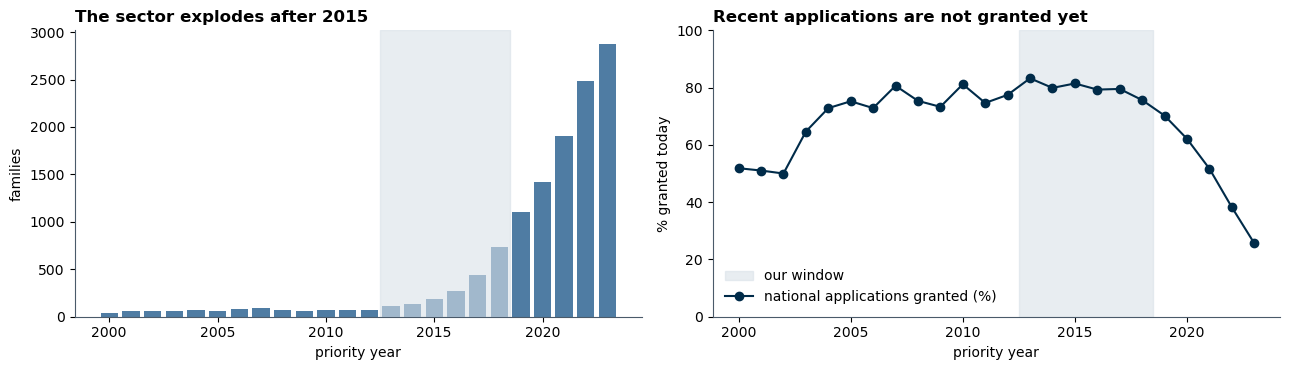

Window 2013-2018: 1,884 families, 5,248 national applications, 606 EP applications


In [6]:
WINDOW = (2013, 2018)       # the priority years we score: see the shaded area

by_year = families_all.groupby("priority_year").size()
grant_rate = national_all.groupby("priority_year").granted.apply(lambda s: (s == "Y").mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(by_year.index, by_year.values, color=BLUE)
axes[0].axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.6)
axes[0].set_xlabel("priority year")
axes[0].set_ylabel("families")
axes[0].set_title("The sector explodes after 2015")

axes[1].axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.6, label="our window")
axes[1].plot(grant_rate.index, grant_rate * 100, marker="o", color=NAVY, label="national applications granted (%)")
axes[1].set_ylim(0, 100)
axes[1].set_xlabel("priority year")
axes[1].set_ylabel("% granted today")
axes[1].legend(frameon=False, loc="lower left")
axes[1].set_title("Recent applications are not granted yet")
plt.tight_layout()
plt.show()

families = families_all[families_all.priority_year.between(*WINDOW)].copy()
FAMILIES = [int(f) for f in families.docdb_family_id]
national = national_all[national_all.docdb_family_id.isin(FAMILIES)]
ep = members[(members.appln_auth == "EP") & members.docdb_family_id.isin(FAMILIES)]      # EP applications of the window
print(f"Window {WINDOW[0]}-{WINDOW[1]}: {len(FAMILIES):,} families, {len(national):,} national applications, "
      f"{len(ep):,} EP applications")

**Design decision to write in the deck.** The window must (a) be long enough to have a few hundred families, and (b) end before the drop of the grant rate and early enough for a 5-year citation window (section 5). The chart is the evidence: if you move `WINDOW`, re-read it.

## 3. The firms: who owns which family?

The owners are the **applicants** of the applications (`applt_seq_nr > 0` in `TLS207`, at every office), with their name `psn_name` and their sector `psn_sector` from `TLS206`. A family filed by two firms together counts for **both** of them (*full counting*). We read the owners of the whole period, 2000-2023.

In [43]:
owners = read(
    lambda ids: db.query(TLS207_PERS_APPLN.appln_id, TLS206_PERSON.psn_name, TLS206_PERSON.psn_sector)
                  .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
                  .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)
                  .filter(TLS207_PERS_APPLN.appln_id.in_(ids)),
    members.appln_id,
)
owners["psn_name"] = owners.psn_name.fillna("").str.strip()
owners["docdb_family_id"] = owners.appln_id.map(members.set_index("appln_id").docdb_family_id)
owners.psn_sector.value_counts(dropna=False)

psn_sector
COMPANY                              17295
UNKNOWN                               7618
UNIVERSITY                            4885
INDIVIDUAL                            3060
GOV NON-PROFIT                        1527
                                       157
GOV NON-PROFIT UNIVERSITY              128
COMPANY UNIVERSITY                       3
COMPANY GOV NON-PROFIT UNIVERSITY        1
COMPANY GOV NON-PROFIT                   1
Name: count, dtype: int64

The sector tells who the applicant is (`COMPANY`, `UNIVERSITY`, `GOV NON-PROFIT`, `INDIVIDUAL`...). We score **firms**, so we keep the `COMPANY` ones. Applicants with an **empty** sector are dropped too: look at the count above, and if a famous name is lost that way, add it by hand in 3.1.

### 3.1 One firm, one name

> ## ⚠️ TO DO · NAME HARMONIZATION NOT DONE YET

In [44]:
# Help for the harmonisation: the 60 most frequent raw company names (families of the whole period)
raw_companies = owners[owners.psn_sector.fillna("").str.contains("COMPANY")]
(raw_companies.groupby("psn_name").docdb_family_id.nunique()
              .sort_values(ascending=False).head(60).rename("families").to_frame())

,families
psn_name,
IBM (INTERNATIONAL BUSINESS MACHINES CORPORATION),768
ORIGIN QUANTUM COMPUTING TECHNOLOGY COMPANY,431
BEIJING BAIDU NETCOM SCIENCE AND TECHNOLOGY COMPANY,331
GOOGLE,242
MICROSOFT TECHNOLOGY LICENSING,241
FUJITSU,222
D-WAVE SYSTEMS,211
国际商业机器公司,201
IBM DEUTSCHLAND,173


In [9]:
# TODO: NAME HARMONIZATION (see the reminder above). Add one line per group of your sector:
GROUPS = {
    # "GROUP NAME": r"PATTERN1|PATTERN2",     # regular expressions on psn_name (names are in capitals)
}


def firm_name(psn_name):
    """The group a name belongs to, or the name itself."""
    for group, pattern in GROUPS.items():
        if re.search(pattern, psn_name):
            return group
    return psn_name


owners["firm"] = owners.psn_name.map(firm_name)
merged = owners[owners.firm != owners.psn_name]
if len(merged):
    print("Names merged into a group:")
    display(merged.groupby(["firm", "psn_name"]).docdb_family_id.nunique().rename("families").to_frame())
else:
    print("⚠️ GROUPS is empty: names are NOT harmonised yet, every name is its own firm.")

companies = owners[owners.psn_sector.fillna("").str.contains("COMPANY")]
fam_firm_all = companies[["docdb_family_id", "firm"]].drop_duplicates()        # one row per (family, firm)
fam_firm = fam_firm_all[fam_firm_all.docdb_family_id.isin(FAMILIES)]          # the window only
print(f"In the window: {fam_firm.firm.nunique():,} companies own {fam_firm.docdb_family_id.nunique():,} "
      f"of the {len(FAMILIES):,} families")

⚠️ GROUPS is empty: names are NOT harmonised yet, every name is its own firm.
In the window: 322 companies own 1,201 of the 1,884 families


### 3.2 Which firms do we score?

**The story is yours to choose.** Quantum computing mixes very different players, and the selection decides which story the deck tells: *big tech and incumbents* (computing, electronics) that file quantum patents next to everything else; *pure players* (start-ups founded around one hardware approach); firms of *Asia* against firms of *the US and Europe*. Look at the table below and choose the firms that give the story you want to tell.

Two parameters, both design choices:

- `N_FIRMS`: how many firms you want to retain (the most interesting for your story: you can also overwrite `TOP` by hand with a list of names);
- `MIN_FAMILIES`: a minimum portfolio. With 3 families, one citation or one refusal changes a rate completely: the indicator is noise. This is the same idea as the Clarivate **volume gate** (at least 100 inventions), scaled to one sector.

In [10]:
N_FIRMS = 15
MIN_FAMILIES = 10

n_families = fam_firm.groupby("firm").docdb_family_id.nunique().sort_values(ascending=False)
TOP = list(n_families[n_families >= MIN_FAMILIES].head(N_FIRMS).index)
# TOP = ["FIRM A", "FIRM B", ...]       # <- or choose the firms by hand, after the harmonisation
SHORT = {f: f.title()[:28] for f in TOP}     # short names for the charts

print(f"We score {len(TOP)} firms (the first {N_FIRMS} with at least {MIN_FAMILIES} families in {WINDOW[0]}-{WINDOW[1]})")
n_families.loc[TOP].rename("families").to_frame()

We score 15 firms (the first 15 with at least 10 families in 2013-2018)


,families
firm,
IBM (INTERNATIONAL BUSINESS MACHINES CORPORATION),188
IBM UNITED KINGDOM,123
INTEL CORPORATION,104
GOOGLE,91
国际商业机器公司,88
MICROSOFT TECHNOLOGY LICENSING,70
D-WAVE SYSTEMS,64
谷歌有限责任公司,61
IBM (CHINA) INVESTMENT COMPANY,42


In [45]:
def firm_bars(values, title, xlabel, fmt="{:.2f}", ref=None, ref_label=None, color=NAVY):
    """One horizontal bar per scored firm, in the order of TOP (largest portfolio on top)."""
    v = values.reindex(TOP)[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(v) + 1.2))
    ax.barh([SHORT[f] for f in v.index], v.values, color=color)
    for y, x in enumerate(v.values):
        if pd.notna(x):
            ax.text(x, y, (" " + fmt.format(x)) if x >= 0 else (fmt.format(x) + " "), va="center",
                    ha="left" if x >= 0 else "right", fontsize=9, color=GREY)
    if ref is not None:
        ax.axvline(ref, color=ORANGE, ls="--", lw=1.2)
        ax.text(ref, len(v) - 0.45, f" {ref_label}", color=ORANGE, fontsize=9, va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def per_firm(column, how="mean"):
    """Aggregate a column of `families` over the families of each scored firm."""
    table = fam_firm.merge(families[["docdb_family_id", column]], on="docdb_family_id")
    return table.groupby("firm")[column].agg(how).reindex(TOP).rename(column)

## 4. Volume: weight in the sector

### 4.1 Basics: share of the sector's families

$$\text{Volume}_f=\frac{\text{families of firm } f}{\text{all families of the sector in the window}}$$

The denominator is **all** the families of the window, including those of universities, research institutes, individuals and small firms: volume is a share of the whole sector. (In quantum computing a large part of the families belongs to universities and public labs: the shares of the firms are therefore smaller than in a sector dominated by companies.)

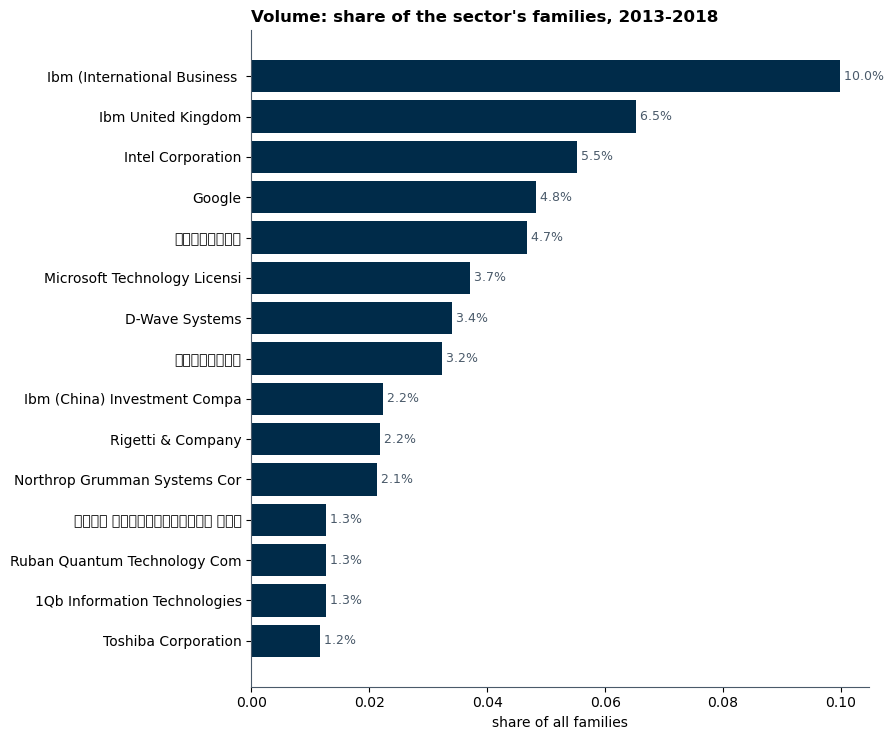

In [12]:
volume = (n_families / len(FAMILIES)).reindex(TOP).rename("volume")
firm_bars(volume, f"Volume: share of the sector's families, {WINDOW[0]}-{WINDOW[1]}", "share of all families", fmt="{:.1%}")

**Thinking about..** Volume measures size, not quality: a firm can file many cheap, narrow patents.

### 4.2 Refinement: shares over time, who gains and who loses?

One number for six years hides the dynamics. The same share, **year by year**, shows changes of power in the sector, and quantum computing has had a **change of regime**: the number of families per year grows many times in a few years (2.3), and new entrants (big tech, start-ups, Chinese firms) take space from the first movers.

$$\text{Share}_{f,t}=\frac{\text{families of firm } f \text{ with priority year } t}{\text{all families of the sector with priority year } t}$$

We plot it over the whole period, smoothed with a 3-year moving average (one year is often a handful of families). The last two years are incomplete because applications are published 18 months after filing; a share suffers less than a count, but read them with care.

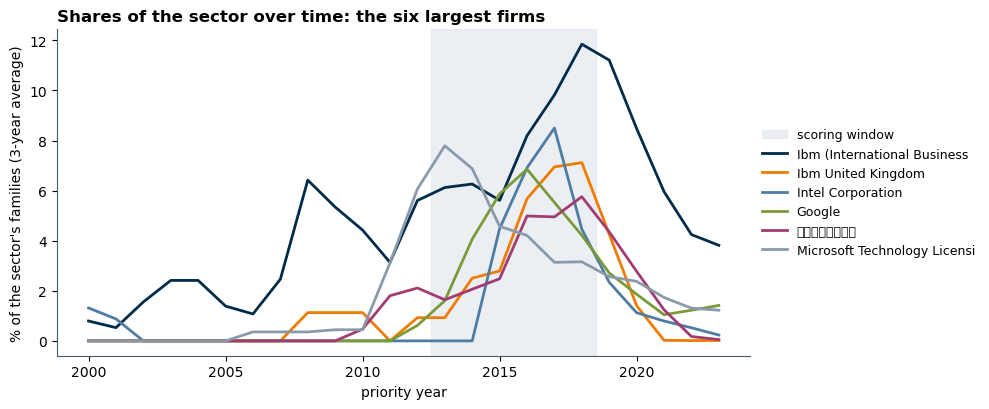

In [13]:
yearly = (fam_firm_all.merge(families_all[["docdb_family_id", "priority_year"]], on="docdb_family_id")
                     .groupby(["priority_year", "firm"]).docdb_family_id.nunique()
                     .unstack(fill_value=0))
total = families_all.groupby("priority_year").docdb_family_id.nunique()
share = yearly.reindex(index=total.index, columns=TOP, fill_value=0).div(total, axis=0)
smooth = share.rolling(3, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.5, label="scoring window")
for k, f in enumerate(TOP[:6]):
    ax.plot(smooth.index, smooth[f] * 100, color=LINES[k], lw=2, label=SHORT[f])
ax.set_xlabel("priority year")
ax.set_ylabel("% of the sector's families (3-year average)")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.set_title("Shares of the sector over time: the six largest firms")
plt.tight_layout()
plt.show()

To turn the dynamics into numbers we compute two changes of share, in percentage points:

- **inside the window**: average share in the second half (2016-2018) minus the average share in the first half (2013-2015);
- **after the window**: average share in the young years (2019-2023) minus the average share in the window. These families are too young to be scored (2.3), but they tell **who is accelerating now**: useful for the story, and a bridge to the future score. The last two years are incomplete.

Positive means the firm is gaining weight.

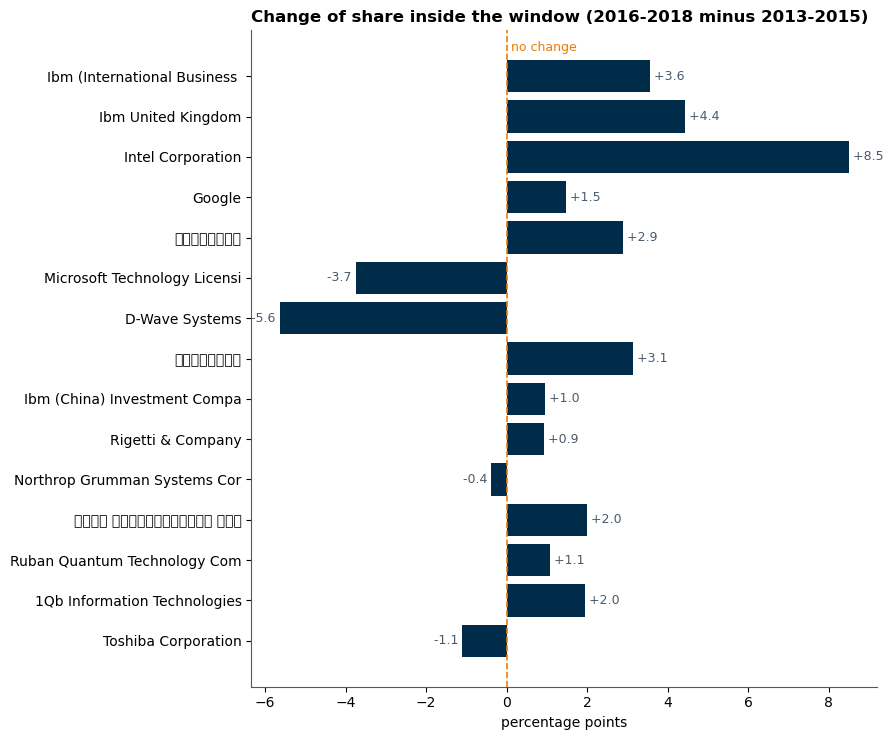

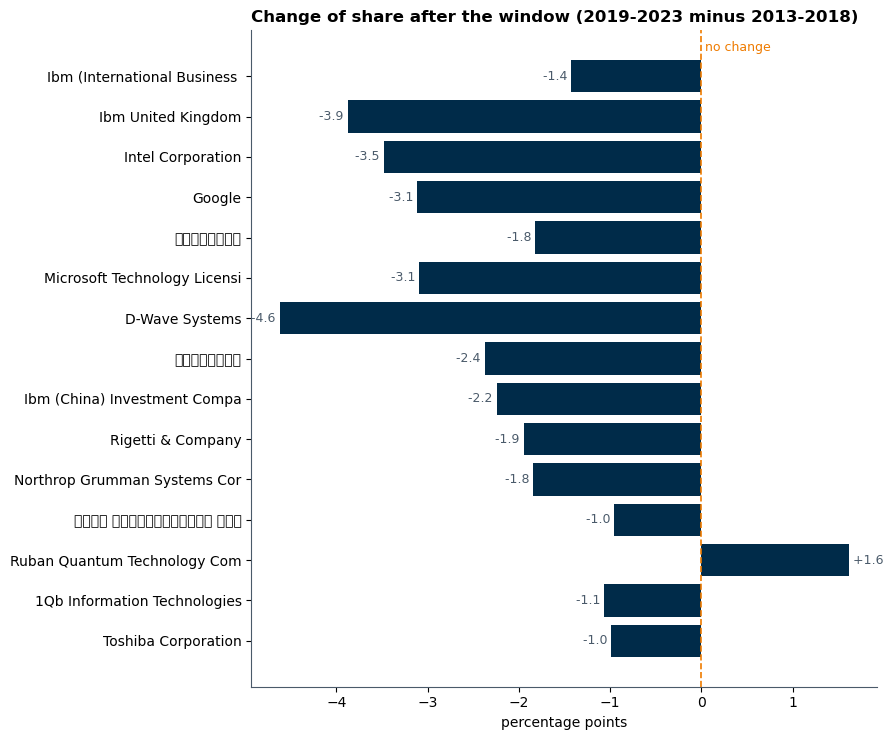

In [14]:
MID_YEAR = 2015
in_window = share.loc[WINDOW[0]:WINDOW[1]]
volume_change = ((in_window.loc[MID_YEAR + 1:].mean() - in_window.loc[:MID_YEAR].mean()) * 100).rename("volume_change")
volume_recent = ((share.loc[WINDOW[1] + 1:].mean() - in_window.mean()) * 100).rename("volume_recent_change")

firm_bars(volume_change, f"Change of share inside the window ({MID_YEAR + 1}-{WINDOW[1]} minus {WINDOW[0]}-{MID_YEAR})",
          "percentage points", fmt="{:+.1f}", ref=0, ref_label="no change")
firm_bars(volume_recent, f"Change of share after the window ({WINDOW[1] + 1}-{ALL_YEARS[1]} minus {WINDOW[0]}-{WINDOW[1]})",
          "percentage points", fmt="{:+.1f}", ref=0, ref_label="no change")

## 5. Influence: technological impact

### 5.1 Basics: forward citations within 5 years, compared with the same cohort

A family is influential if later inventions **build on it**, so we count its forward citations, as in the lecture:

- **between families**: `TLS228_DOCDB_FAM_CITN` has one row per pair *citing family → cited family*, collecting the citations made by any publication of one family to any publication of the other;
- **within 5 years** of the first publication of the cited family, so that old and young families have the same time to be cited. The date of a citation is the first publication year of the **citing** family;
- we drop a family citing itself; citations from the same firm (self-citations) stay in, as in the OECD indicators.

First, the citations and their dates:

In [15]:
fcit = read(
    lambda ids: db.query(
        TLS228_DOCDB_FAM_CITN.docdb_family_id.label("citing_family"),
        TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("cited_family"),
    ).filter(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.in_(ids)),
    FAMILIES,
).drop_duplicates()
fcit = fcit[fcit.citing_family != fcit.cited_family]

citing_years = read(
    lambda ids: db.query(TLS201_APPLN.docdb_family_id, func.min(TLS201_APPLN.earliest_publn_year).label("year"))
                  .filter(TLS201_APPLN.docdb_family_id.in_(ids))
                  .filter(TLS201_APPLN.earliest_publn_year < 9999)
                  .group_by(TLS201_APPLN.docdb_family_id),
    fcit.citing_family.unique(),
).groupby("docdb_family_id").year.min()
fcit["citing_year"] = fcit.citing_family.map(citing_years)
fcit["cited_year"] = fcit.cited_family.map(families.set_index("docdb_family_id").first_publn_year)
fcit["lag"] = fcit.citing_year - fcit.cited_year          # years between the two first publications
print(f"{len(fcit):,} citing-cited pairs, from {fcit.citing_family.nunique():,} citing families")

40,342 citing-cited pairs, from 16,486 citing families


A raw count is unfair across years and fields (lecture, *Comparing forward citations fairly*): older families had more citing patents around them, and citation habits differ a lot between technical fields (a software patent and a hardware one are not cited alike). So we divide each family's count by the **mean of the families of the same cohort: same CPC subclass `s` and same priority year `t`**.

$$\text{fwd}^{norm}_{i}=\frac{\text{fwd}_{i}}{\bar F_{s,t}}\qquad\text{with}\qquad \bar F_{s,t}=\frac{1}{N_{s,t}}\sum_{j\,\in\,(s,t)}\text{fwd}_{j}$$

- $\text{fwd}_i$: citations received by family $i$ within 5 years; $s$ is its CPC subclass (the most frequent among its applications, 2.2) and $t$ its priority year;
- $N_{s,t}$: the number of families of the sector in the same subclass and priority year.

A value of **1** means "cited as much as the average family of the same subclass and year"; 2 means twice as much.

**A cohort can be too small.** The sample has a few hundred families per year spread on several subclasses: some cohorts have 1 or 2 families, and a mean of 2 families is not a benchmark. When a cohort has fewer than `MIN_COHORT` families **with a complete window**, we compare the family with the average of its priority year alone (all subclasses): a design choice, written here and in the appendix. Families without CPC code (`NONE`) always use the year.

We write it as a function of the window `w`, because the refinements use other windows. A window is counted only if the data cover it: PATSTAT has the citations up to about 2025 (`LAST_YEAR`, **check it on your edition**), so a family first published in 2022 has no complete 5-year window, and its value is set to *missing* rather than to a count that is too low.

In [16]:
LAST_YEAR = 2025                          # last year of citations covered by the PATSTAT edition
COHORT = ["cpc4", "priority_year"]        # field x year
MIN_COHORT = 5                            # smaller cohorts fall back to the priority year alone


def forward_citations(w):
    """Citations received within w years of the first publication; missing if the window is not complete."""
    counts = fcit[fcit.lag.between(0, w)].groupby("cited_family").citing_family.nunique()
    fwd = families.docdb_family_id.map(counts).fillna(0)
    complete = families.first_publn_year + w <= LAST_YEAR
    return fwd.where(complete)


def normalise_by_cohort(values):
    """Each family's value divided by the mean of its cohort (subclass x year); small cohorts use the year only."""
    keys = [families[c] for c in COHORT]
    fine_mean = values.groupby(keys).transform("mean")
    fine_size = values.groupby(keys).transform("count")
    year_mean = values.groupby(families["priority_year"]).transform("mean")
    use_fine = (fine_size >= MIN_COHORT) & (families.cpc4 != "NONE")
    mean_cohort = fine_mean.where(use_fine, year_mean)
    return (values / mean_cohort).where(mean_cohort > 0, 0.0).where(values.notna())


families["fwd5"] = forward_citations(5)
families["fwd5_norm"] = normalise_by_cohort(families.fwd5)

ok = families.fwd5.notna()
sizes = families[ok].groupby(COHORT).docdb_family_id.transform("size")
print(f"Families with a complete 5-year window: {ok.mean():.0%} of the window")
print(f"Of these, {(sizes >= MIN_COHORT).mean():.0%} are compared inside their subclass x year cohort, "
      f"the others with their year")
families.groupby("priority_year").fwd5.mean().round(2).to_frame("mean fwd5 (all subclasses)").T

Families with a complete 5-year window: 97% of the window
Of these, 84% are compared inside their subclass x year cohort, the others with their year


priority_year,2013,2014,2015,2016,2017,2018
mean fwd5 (all subclasses),22.24,17.28,22.15,25.54,16.35,13.04


Read the means by year: they move from year to year, and they fall in the last years because younger families are cited less or the data stop. The normalisation removes this, because each family is compared only with the families of its own cohort. The influence of a firm is the **average** of its families:

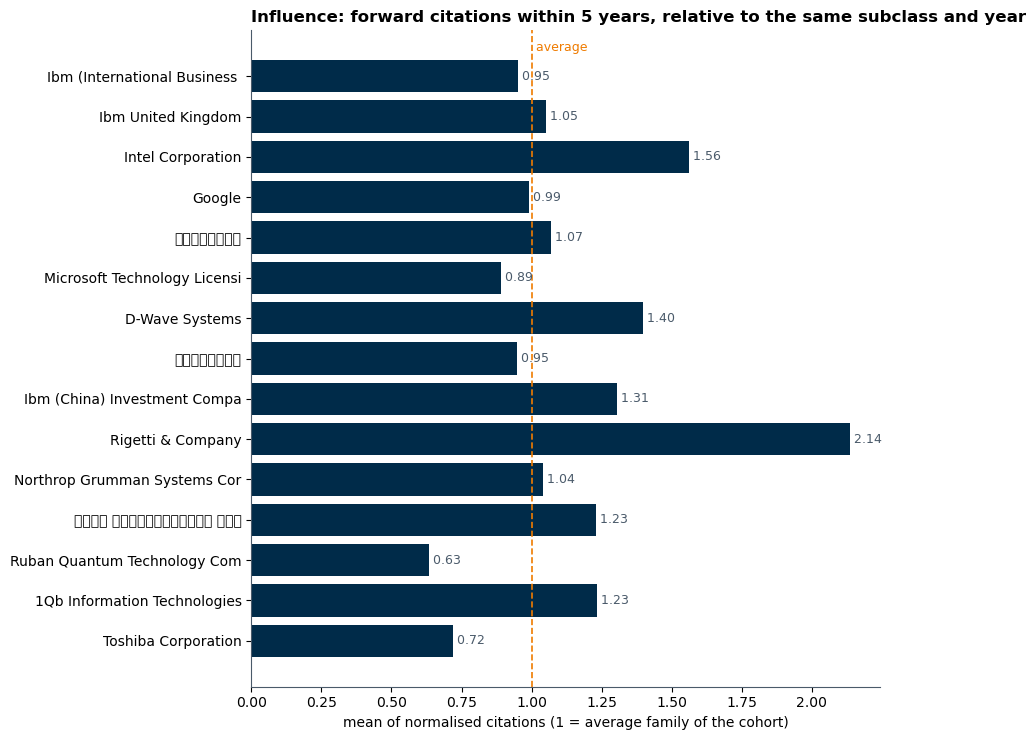

In [17]:
influence = per_firm("fwd5_norm").rename("influence")
firm_bars(influence, "Influence: forward citations within 5 years, relative to the same subclass and year",
          "mean of normalised citations (1 = average family of the cohort)", ref=1, ref_label="average")

**Watch out.** An average is pulled up by one star family: a firm with 9 uncited families and one blockbuster can look influential. Refinement 5.4 looks at the top of the distribution instead.

### 5.2 Refinement: a shorter or a longer window (3 and 7 years)

A short window measures how fast a family is noticed; a long one is closer to its total impact, but the last priority years have no complete window yet, so it rests on the older families only. In a young sector this matters: **read the share of families with a complete window**. Does the window change the story?

In [18]:
for w in [3, 7]:
    families[f"fwd{w}_norm"] = normalise_by_cohort(forward_citations(w))

by_window = pd.concat([per_firm(f"fwd{w}_norm") for w in [3, 5, 7]], axis=1)
by_window.columns = ["3 years", "5 years", "7 years"]
print("Families with a complete window:",
      {w: f"{families[f'fwd{w}_norm'].notna().mean():.0%}" for w in [3, 5, 7]})
print("Rank correlation with the 5-year ranking:",
      by_window.corr(method="spearman")["5 years"].drop("5 years").round(2).to_dict())
by_window.rename(index=SHORT).round(2)

Families with a complete window: {3: '99%', 5: '97%', 7: '54%'}
Rank correlation with the 5-year ranking: {'3 years': 0.95, '7 years': 0.85}


,3 years,5 years,7 years
firm,,,
Ibm (International Business,0.99,0.95,1.11
Ibm United Kingdom,1.08,1.05,1.32
Intel Corporation,1.74,1.56,1.29
Google,0.92,0.99,1.03
国际商业机器公司,1.09,1.07,1.39
Microsoft Technology Licensi,0.85,0.89,0.92
D-Wave Systems,1.35,1.40,1.43
谷歌有限责任公司,0.84,0.95,0.90
Ibm (China) Investment Compa,1.37,1.31,1.36


If the order of the firms is the same in the three columns, the choice of the window does not matter much. A firm that climbs with the longer window has patents noticed late but used for long.

### 5.3 Refinement: who cites the firm, competitors or examiners?

A citation can be added by the **applicant** of the citing patent (origin `APP` in `TLS212`) or by the **examiner** during the search or examination (`SEA`, `ISR`, `SUP`, `EXA`...). The difference matters (lecture on knowledge spillovers):

- an **applicant** citation means that a competitor *knew* the patent when it filed: a real knowledge flow, and visibility in the market;
- an **examiner** citation means that the patent is relevant prior art, which the citing applicant may never have read.

The origin is recorded at the level of **publications**, so we go from our families to their publications (`TLS211`), then to the publications that cite them. We keep only citing **EP** publications: at the USPTO applicants must disclose all the prior art they know, so US applicant citations would mix two different practices (Tutorial 3). Change `CITING_OFFICES` if you want to look at other offices.

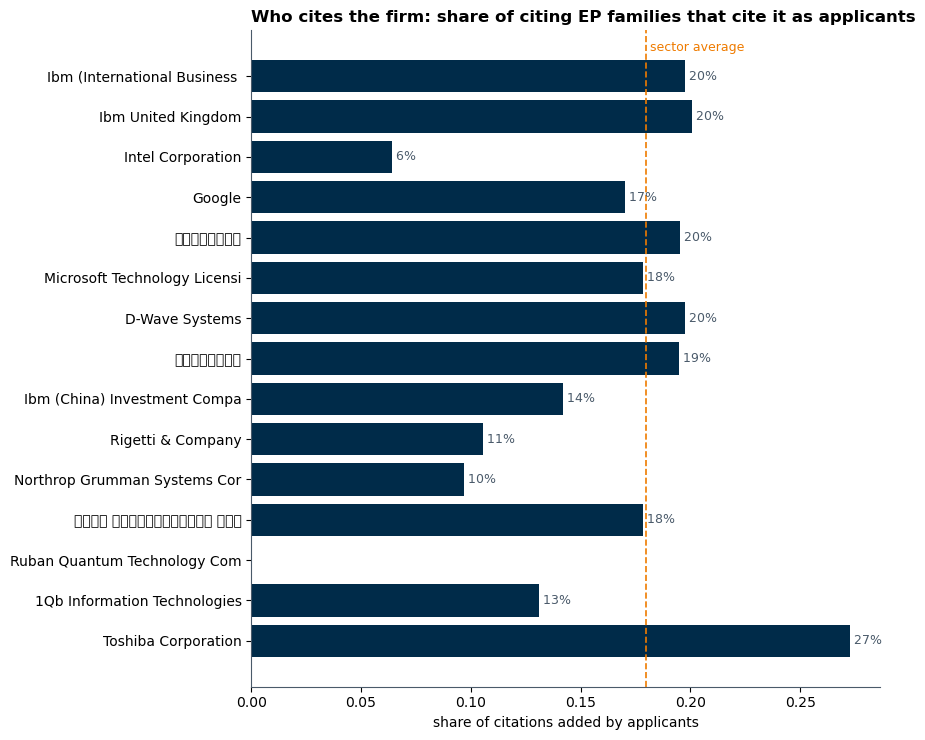

In [19]:
CITING_OFFICES = ["EP"]

# 1. All the publications of the families of the window (any office)
pubs = read(
    lambda ids: db.query(TLS211_PAT_PUBLN.pat_publn_id, TLS201_APPLN.docdb_family_id.label("cited_family"))
                  .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
                  .filter(TLS201_APPLN.docdb_family_id.in_(ids)),
    FAMILIES,
).drop_duplicates("pat_publn_id")

# 2. The citations they receive, with their origin
cit = read(
    lambda ids: db.query(TLS212_CITATION.pat_publn_id.label("citing_publn"), TLS212_CITATION.citn_replenished,
                         TLS212_CITATION.citn_id, TLS212_CITATION.citn_origin, TLS212_CITATION.cited_pat_publn_id)
                  .filter(TLS212_CITATION.cited_pat_publn_id.in_(ids)),
    pubs.pat_publn_id,
)
cit["cited_family"] = cit.cited_pat_publn_id.map(pubs.set_index("pat_publn_id").cited_family)

# 3. The office and the family of each citing publication
citing_info = read(
    lambda ids: db.query(TLS211_PAT_PUBLN.pat_publn_id.label("citing_publn"), TLS211_PAT_PUBLN.publn_auth.label("citing_office"),
                         TLS201_APPLN.docdb_family_id.label("citing_family"))
                  .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
                  .filter(TLS211_PAT_PUBLN.pat_publn_id.in_(ids)),
    cit.citing_publn.unique(),
).drop_duplicates("citing_publn")
cit = cit.merge(citing_info, on="citing_publn")
cit = cit[cit.citing_family != cit.cited_family]
cit["citing_office"] = cit.citing_office.str.strip()
cit["who"] = np.where(cit.citn_origin.fillna("").str.strip() == "APP", "applicant", "examiner or other")

ep_cit = (cit[cit.citing_office.isin(CITING_OFFICES)]
          .drop_duplicates(["citing_family", "cited_family", "who"])
          .merge(fam_firm, left_on="cited_family", right_on="docdb_family_id"))
applicant_share = (ep_cit.who == "applicant").groupby(ep_cit.firm).mean().reindex(TOP).rename("applicant_share")
firm_bars(applicant_share, "Who cites the firm: share of citing EP families that cite it as applicants",
          "share of citations added by applicants", fmt="{:.0%}",
          ref=(ep_cit.who == "applicant").mean(), ref_label="sector average")

A firm with a high applicant share is **watched by its competitors**: its patents are known reference points. Read it with the number of citations: 50% of 4 citations says little.

### 5.4 Refinement: blocking patents, X and I citations at the top of the sector

Not all citations are equal. In a search report the examiner gives each cited document a **category** (`TLS215_CITN_CATEG`):

| Category | Meaning for the citing application |
|---|---|
| **X** | the cited document **alone** destroys the novelty or the inventive step of the claim |
| **I** | the cited document **alone** destroys the inventive step of the claim (EPO, since 2012) |
| Y | relevant only in combination with another document |
| A | general background |

A family often cited as **X or I** stood in the way of later applications: competitors had to narrow their claims or give up. It is a **blocking patent**, the strongest form of influence. `CITN_CATEG` can hold several letters (e.g. `XI`), so we look for an X or an I anywhere in it.

For each family we count the distinct families that cite it as X or I, and we call **blocking** the families in the **top 10% of their priority year**, with at least one such citation. Here we compare within the **year only** (not subclass × year): a 10% cut on cohorts of a few families makes no sense. As in 5.1, comparing inside the year is fair to young families.

Each family is then **blocking (1) or not (0)**. For a firm we compute two numbers from these 0/1 values:

$$\text{Blocking share}_f=\frac{\text{blocking families of } f}{\text{families of } f}\qquad\qquad \text{Share of the sector's blocking}_f=\frac{\text{blocking families of } f}{\text{all blocking families of the sector}}$$

The first is the average of the 0/1 values over the firm's families: the share of its portfolio that blocks others.

In [20]:
TOP_SHARE = 0.10              # top 10% of each priority year

categ = read(
    lambda ids: db.query(TLS215_CITN_CATEG.pat_publn_id.label("citing_publn"), TLS215_CITN_CATEG.citn_replenished,
                         TLS215_CITN_CATEG.citn_id, TLS215_CITN_CATEG.citn_categ)
                  .filter(TLS215_CITN_CATEG.pat_publn_id.in_(ids)),
    cit.citing_publn.unique(),
)
xi_keys = categ[categ.citn_categ.fillna("").str.contains("X|I", regex=True)][["citing_publn", "citn_replenished", "citn_id"]]
xi = cit.merge(xi_keys.drop_duplicates(), on=["citing_publn", "citn_replenished", "citn_id"])

families["xi"] = families.docdb_family_id.map(xi.groupby("cited_family").citing_family.nunique()).fillna(0)
threshold = families.groupby("priority_year").xi.transform(lambda s: s.quantile(1 - TOP_SHARE))   # cut-off of each year
families["blocking"] = ((families.xi >= threshold) & (families.xi > 0)).astype(int)

owners_of = fam_firm.groupby("docdb_family_id").firm.agg(", ".join)     # co-owned families: all owners
print(f"Blocking families: {families.blocking.sum():,} of {len(families):,}. The ten strongest:")
(families.assign(owners=families.docdb_family_id.map(owners_of).fillna("(not a company)"))
         .sort_values("xi", ascending=False)[["docdb_family_id", "priority_year", "cpc4", "xi", "owners"]].head(10))

Blocking families: 263 of 1,884. The ten strongest:


,docdb_family_id,priority_year,cpc4,xi,owners
1726,63014052,2016,G05D,27.0,STATE FARM MUTUAL AUTOMOBILE INSURANCE CO...
1076,54554938,2014,G06N,20.0,RIGETTI & COMPANY
1530,60935992,2017,H10W,11.0,"GOOGLE, グーグル エルエルシーＧＯＯＧＬＥ ＬＬＣ, 谷歌有限责任公司"
1634,61830250,2016,H10W,11.0,(not a company)
1850,63919294,2017,H04L,10.0,ANONOS
2426,67301223,2018,G06N,9.0,"BIOVENTURES, バイオベンチャーズ・リミテッド・ライアビリティ・カンパニ..."
1327,58662742,2015,H10W,9.0,(not a company)
1844,63853982,2013,H04L,9.0,ANONOS
2723,68766205,2018,G06N,8.0,ATOM COMPUTING
1655,62091366,2015,H10W,8.0,RIGETTI & COMPANY


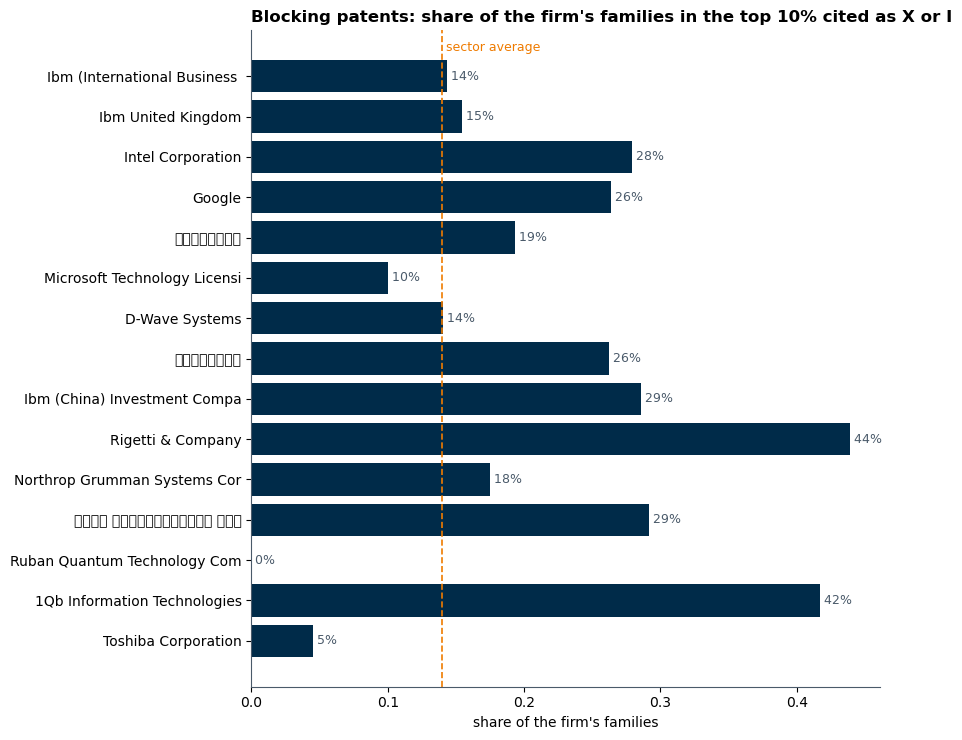

,blocking families,blocking_share,share_of_sector_blocking
firm,,,
Ibm (International Business,27,0.14,0.10
Ibm United Kingdom,19,0.15,0.07
Intel Corporation,29,0.28,0.11
Google,24,0.26,0.09
国际商业机器公司,17,0.19,0.06
Microsoft Technology Licensi,7,0.10,0.03
D-Wave Systems,9,0.14,0.03
谷歌有限责任公司,16,0.26,0.06
Ibm (China) Investment Compa,12,0.29,0.05


In [21]:
blocking_share = per_firm("blocking").rename("blocking_share")                 # mean of 0/1 = share of families
blocking_power = (per_firm("blocking", "sum") / families.blocking.sum()).rename("share_of_sector_blocking")

firm_bars(blocking_share, f"Blocking patents: share of the firm's families in the top {TOP_SHARE:.0%} cited as X or I",
          "share of the firm's families", fmt="{:.0%}", ref=families.blocking.mean(), ref_label="sector average")
pd.concat([per_firm("blocking", "sum").rename("blocking families"), blocking_share, blocking_power],
          axis=1).rename(index=SHORT).round(2)

Two readings: `blocking_share` is the **quality** of the portfolio (how many of its families block others), `share_of_sector_blocking` is the **power** in the sector (how many of the sector's blocking patents the firm owns). A small firm can have a high share and little power; a large firm the opposite.

## 6. Success: quality as judged by the examiners

Success asks: **when the firm applies for a patent, do the examiners accept it?** A granted patent has passed an examination of novelty and inventive step, so a high grant rate signals inventions of good quality and well-drafted applications.

Our families are filed at **many offices**, each with its own rules and speed, so we have more than one way to measure it:

| | 6.1 Success of the firm (basics) | 6.2 Success at the EPO (refinement) | 6.3 Success by invention (refinement) |
|---|---|---|---|
| What we count | all the firm's **national applications**, at every office | the firm's **EP applications** | the firm's **inventions** (families) |
| Who judges | every office, each with its own standards | always the **EPO** | every office, averaged inside the family |
| Strength | uses all the data: it is the suggested definition (granted ÷ filed) | the same judge for every firm: a fair comparison | rewards inventions that pass several different examinations |
| Limit | the mix of offices depends on where the firm files: a firm filing mostly in a fast office looks better | says nothing about the other markets; few EP applications for some firms | depends on where the firm chooses to file |

### 6.1 Basics: share of national applications granted, on filings old enough

$$\text{Success}_f=\frac{\text{granted applications of firm } f}{\text{applications of firm } f}$$

We count the **national applications** of the firm's families, filed at any office. Two kinds of family members are **not** national applications, and we leave them out:

- `WO`: a PCT application is a request, not protection in a country;
- applications of kind **`T`** (`appln_kind` in `TLS201`): some offices (Spain, Poland, Portugal, Denmark, Austria...) record the **translation of a granted EP patent** as a national application. It is the EP patent validated in that country, not a second examination: it is always "granted", and counting it would inflate both success and globalization.

"**On filings old enough to have been decided**" is the window of 2.3: only priority years up to `WINDOW[1]`. `granted` is `Y` when PATSTAT has an indication of a grant, `N` otherwise: `N` mixes refused, withdrawn and still pending applications, and the window keeps the pending ones few.

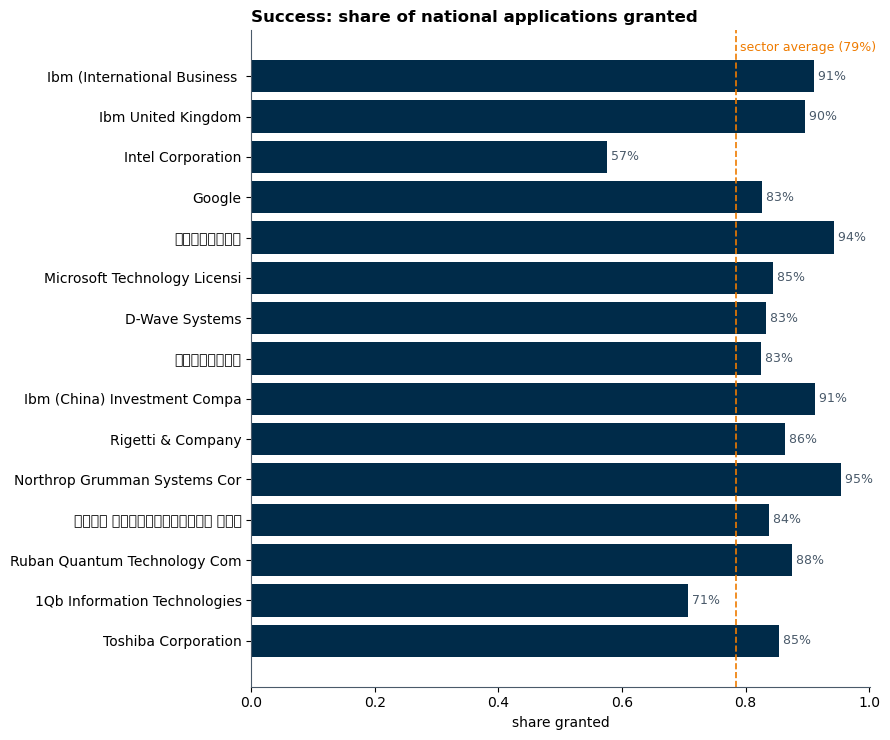

In [22]:
apps = national[["appln_id", "docdb_family_id", "appln_auth", "granted"]].merge(fam_firm, on="docdb_family_id")
success = apps.groupby("firm").granted.apply(lambda s: (s == "Y").mean()).reindex(TOP).rename("success")
sector_rate = (national.granted == "Y").mean()

firm_bars(success, "Success: share of national applications granted", "share granted", fmt="{:.0%}",
          ref=sector_rate, ref_label=f"sector average ({sector_rate:.0%})")

How different are the offices? The grant rate of the applications of our families, by office (offices with at least 20 applications). A firm that files mostly where the rate is high gets a high success without having better patents: this is the limit of 6.1.

In [23]:
office_rate = national.groupby("appln_auth").agg(applications=("appln_id", "size"),
                                                  granted=("granted", lambda s: (s == "Y").mean()))
office_rate[office_rate.applications >= 20].sort_values("granted", ascending=False).round(2).T

appln_auth,FR,JP,TW,US,AU,KR,CN,CA,EP,GB,DE,SG
applications,23.00,504.00,30.0,2167.00,242.00,212.00,942.00,259.00,606.00,105.00,31.00,40.0
granted,0.96,0.91,0.9,0.87,0.86,0.85,0.73,0.65,0.65,0.54,0.29,0.0


### 6.2 Refinement: success at the EPO, one judge for every firm

Same formula, but only the firm's **EP applications**: the examiner is always the EPO, so the comparison between firms is cleaner. The price: firms with few EP applications have a noisy rate, so we show the number of applications and mark the firms with fewer than `MIN_EP_APPS` as missing.

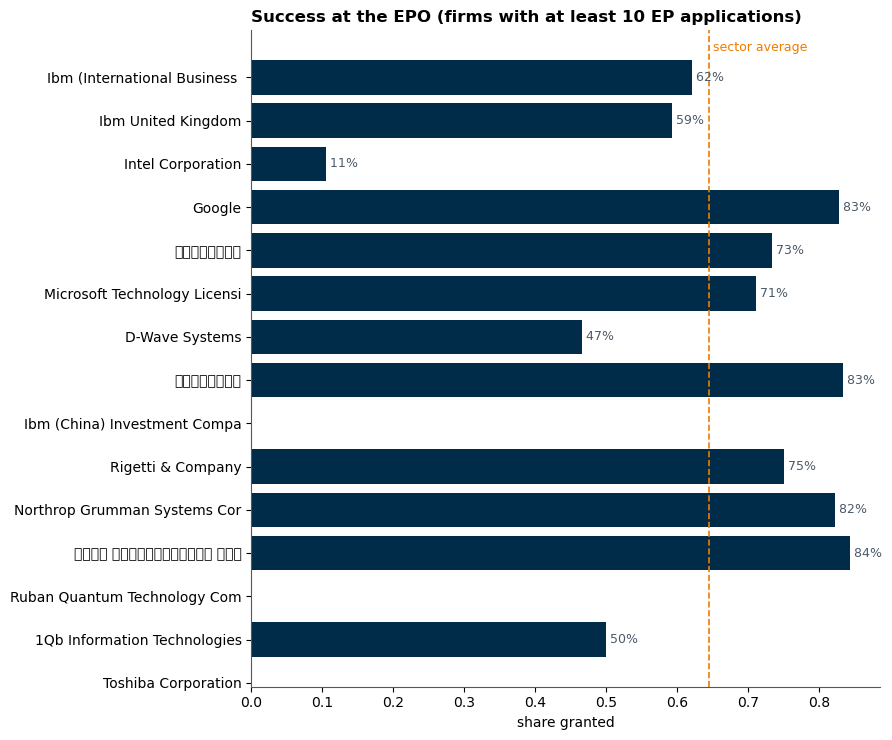

In [24]:
MIN_EP_APPS = 10

ep_apps = ep[["appln_id", "docdb_family_id", "granted"]].merge(fam_firm, on="docdb_family_id")
ep_n = ep_apps.groupby("firm").size().reindex(TOP).fillna(0).astype(int).rename("EP applications")
success_ep = (ep_apps.groupby("firm").granted.apply(lambda s: (s == "Y").mean())
                     .reindex(TOP).where(ep_n >= MIN_EP_APPS).rename("success_ep"))

firm_bars(success_ep, f"Success at the EPO (firms with at least {MIN_EP_APPS} EP applications)", "share granted", fmt="{:.0%}",
          ref=(ep.granted == "Y").mean(), ref_label="sector average")

### 6.3 Refinement: success across offices, invention by invention

Change the unit, from applications to **inventions**:

1. for each family, the share of its national applications that are granted: an invention with 3 grants out of 4 applications gets 75%, one with 1 out of 1 gets 100%;
2. for each firm, the average over its families: (75% + 100%) ÷ 2 = 88%.

An invention granted at the EPO, in the USA, in China and in Japan has passed four different examinations: a strong signal; and a firm with many applications in one family does not weigh more than a firm with one.

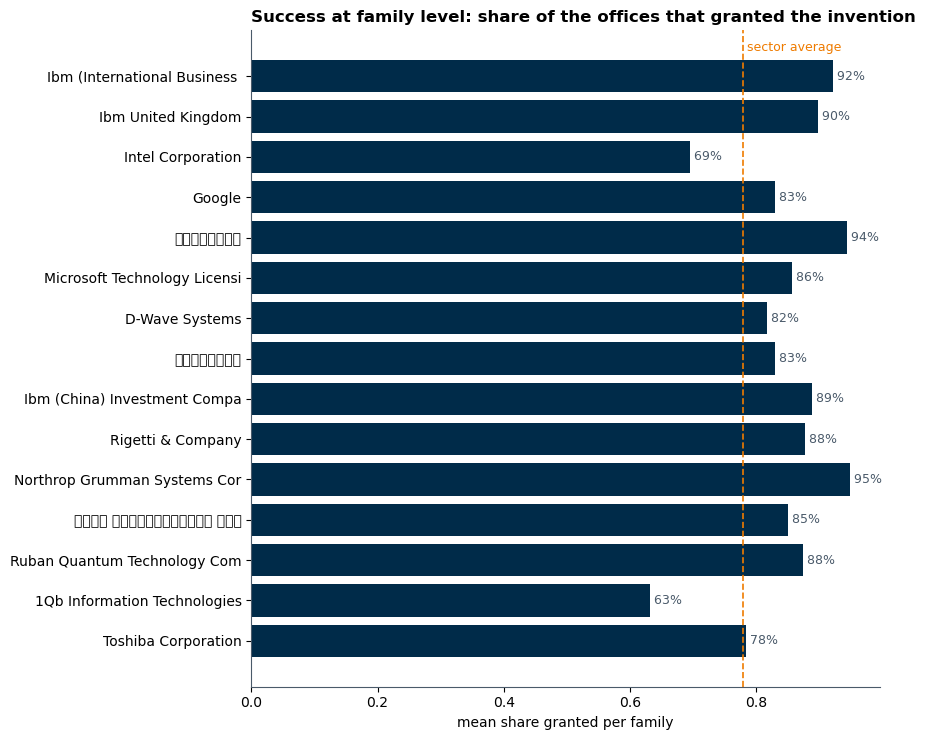

,6.1 all offices,6.2 EPO,EP applications,6.3 by invention
firm,,,,
Ibm (International Business,0.91,0.62,58,0.92
Ibm United Kingdom,0.90,0.59,54,0.90
Intel Corporation,0.57,0.11,19,0.69
Google,0.83,0.83,111,0.83
国际商业机器公司,0.94,0.73,45,0.94
Microsoft Technology Licensi,0.85,0.71,52,0.86
D-Wave Systems,0.83,0.47,15,0.82
谷歌有限责任公司,0.83,0.83,90,0.83
Ibm (China) Investment Compa,0.91,NaN,3,0.89


In [25]:
families["family_success"] = families.docdb_family_id.map(
    national.groupby("docdb_family_id").granted.apply(lambda s: (s == "Y").mean()))
family_success = per_firm("family_success")

firm_bars(family_success, "Success at family level: share of the offices that granted the invention",
          "mean share granted per family", fmt="{:.0%}", ref=families.family_success.mean(), ref_label="sector average")
pd.concat([success, success_ep, ep_n, family_success], axis=1).rename(
    columns={"success": "6.1 all offices", "success_ep": "6.2 EPO", "family_success": "6.3 by invention"}
).rename(index=SHORT).round(2)

**Reading the columns together**

- high in **all**: the firm's inventions are accepted by the EPO and elsewhere;
- high in 6.1, low in 6.2: its applications pass in other offices but meet resistance at the EPO (typical of firms that file in fast offices);
- low in 6.1, high in 6.3: a few families with many refused applications weigh on the pooled rate, but most inventions are granted somewhere.

## 7. Globalization: breadth of market protection

### 7.1 Basics: offices per family

Protecting an invention in many countries is expensive, so firms do it only for inventions they expect to be worth it (lecture, *Family size*; Harhoff, Scherer & Vopel, 2003). For each family we count the distinct **jurisdictions** (offices, `appln_auth`) of its applications:

- we use the national applications of 6.1: no `WO` (a PCT request is not protection) and no kind `T` (translations of EP patents: they are the EP patent validated in a country, and refinement 7.3 counts them properly);
- `EP` counts as one office here; refinement 7.3 opens it up into states.

$$\text{Globalization}_f=\text{mean number of distinct offices per family of firm } f$$

Families with no national application (only PCT or nothing yet): 2.4%
Most frequent offices in the families of the sector:
appln_auth
US    2167
CN     942
EP     606
JP     504
CA     259
AU     242
KR     212
GB     105


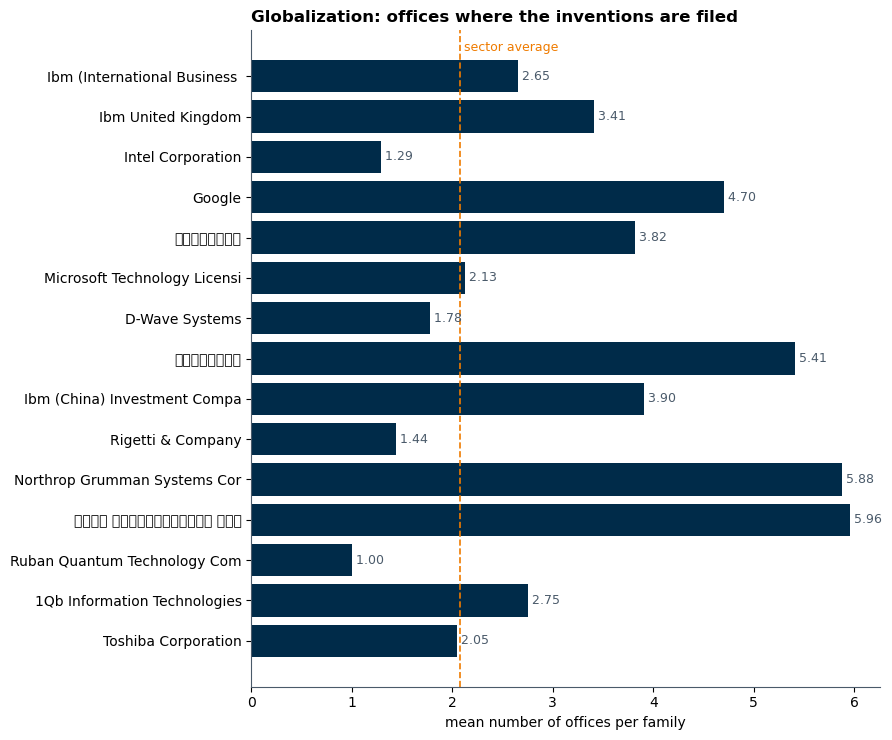

In [26]:
families["offices"] = families.docdb_family_id.map(national.groupby("docdb_family_id").appln_auth.nunique()).fillna(0)
globalization = per_firm("offices").rename("globalization")

print(f"Families with no national application (only PCT or nothing yet): {(families.offices == 0).mean():.1%}")
print("Most frequent offices in the families of the sector:")
print(national.appln_auth.value_counts().head(8).to_string())
firm_bars(globalization, "Globalization: offices where the inventions are filed",
          "mean number of offices per family", ref=families.offices.mean(), ref_label="sector average")

### 7.2 Refinement: family size from the CSV

The CSV has `docdb_family_size`: the number of applications of the family, counted by DOCDB. It is the classic proxy of the value of a patent (the more members, the more the owner paid to protect it). It counts **all** members (also `WO` and kind `T`, and several applications in the same office), so it is a cruder measure than the offices of 7.1, but it is already there. The value is a snapshot of the moment when the CSV was made.

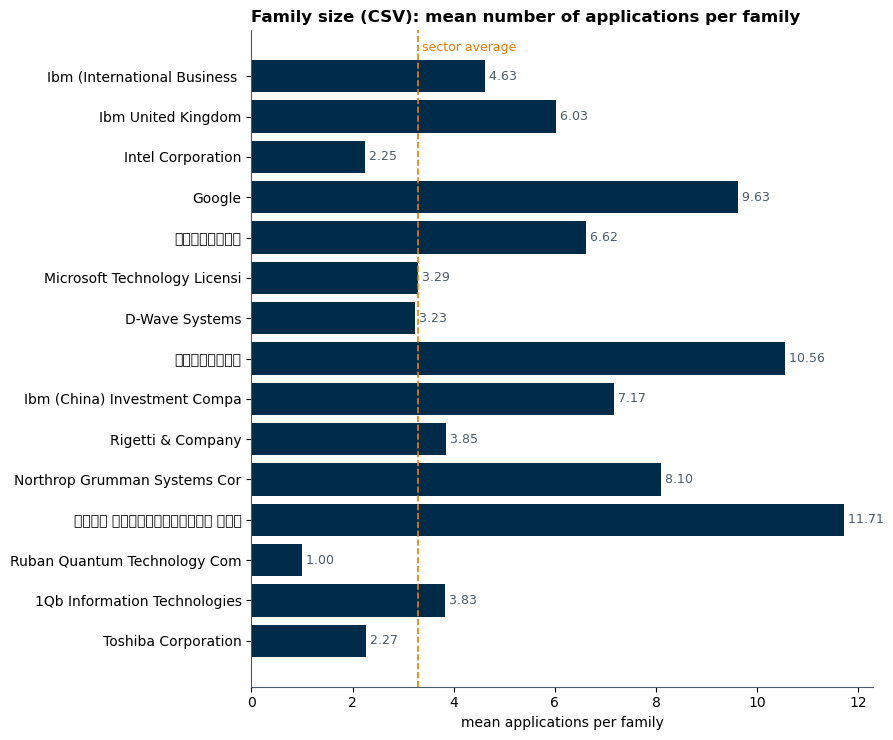

In [27]:
family_size = per_firm("csv_family_size").rename("family_size")
firm_bars(family_size, "Family size (CSV): mean number of applications per family", "mean applications per family",
          ref=families.csv_family_size.mean(), ref_label="sector average")

### 7.3 Refinement: in which European states are the EP patents validated?

A granted EP patent is not yet protection anywhere: the owner must **validate** it in each state (the total of possible EPC states is 40, as per June 2026) where it wants protection (translations, fees), and then pay a **renewal** fee every year in each of them. The number of states is a strong signal of how much the owner values the patent, because each state costs money every year.

PATSTAT has this in the **legal events** (`TLS231`), not in `TLS201`. Three event codes describe the life of an EP patent in each state (data catalog, `EVENT_CODE`):

| Code | Meaning | Country in |
|---|---|---|
| `PGFP` | annual fee paid to a national office: the patent is (or was) valid there | `fee_country` |
| `VSFP` | annual fee paid to a **validation state** outside the EPC (e.g. Morocco) | `fee_country` |
| `PG25` | patent **lapsed** in a state, with the reason in `lapse_text` | `lapse_country` |

`PG25` needs care, because its reason changes everything:

- *"lapse because of **non-payment of due fees**"*: the patent was valid there, then the owner stopped paying. **Validated.**
- *"lapse because of **failure to submit a translation** of the description or to pay the fee within the prescribed time-limit"*: the owner never validated the patent there. **Not validated.**

So a state counts as validated if it has a `PGFP` or `VSFP`, or a `PG25` for non-payment of fees. **Quantum computing note:** only the **granted EP applications** of the window have validated states; the indicator is defined for the firms that have some (it will be missing for the others), and the families are young, so many patents have paid few annual fees yet. Source for all the codes: https://www.epo.org/en/searching-for-patents/data/coverage/weekly

391 granted EP applications in the window
Events by code: {'PG25': 11639, 'PGFP': 1371}


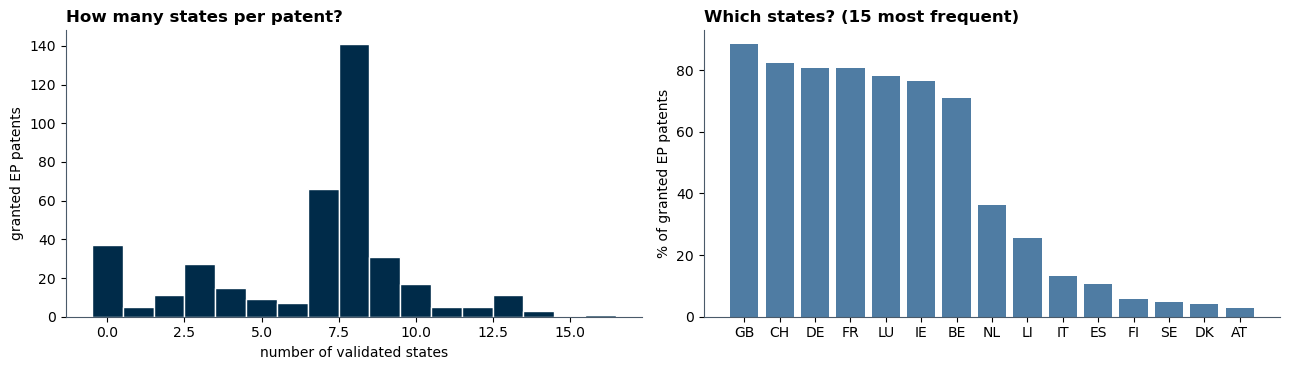

Granted EP patents with no validation event: 9%


In [28]:
ep_granted = [int(i) for i in ep.loc[ep.granted == "Y", "appln_id"]]
events_val = read(
    lambda ids: db.query(TLS231_INPADOC_LEGAL_EVENT.appln_id, TLS231_INPADOC_LEGAL_EVENT.event_code,
                         TLS231_INPADOC_LEGAL_EVENT.fee_country, TLS231_INPADOC_LEGAL_EVENT.lapse_country,
                         TLS231_INPADOC_LEGAL_EVENT.lapse_text)
                  .filter(TLS231_INPADOC_LEGAL_EVENT.appln_id.in_(ids))
                  .filter(TLS231_INPADOC_LEGAL_EVENT.event_code.in_(["PGFP", "VSFP", "PG25"])),
    ep_granted,
)
events_val["lapse_text"] = events_val.lapse_text.fillna("").str.upper()
print(f"{len(ep_granted):,} granted EP applications in the window")
print("Events by code:", events_val.event_code.value_counts().to_dict())

# validated = fee paid (PGFP, VSFP), or lapsed for non-payment after being valid (PG25 + NON-PAYMENT)
lapsed_after_valid = (events_val.event_code == "PG25") & events_val.lapse_text.str.contains("NON-PAYMENT")
val = events_val[events_val.event_code.isin(["PGFP", "VSFP"]) | lapsed_after_valid].copy()
val["country"] = np.where(val.event_code == "PG25", val.lapse_country, val.fee_country)
val["country"] = val.country.fillna("").str.strip()
val = val[(val.country != "") & (val.country != "EP")].drop_duplicates(["appln_id", "country"])

states = val.groupby("appln_id").country.nunique()
n_states = pd.Series(ep_granted, dtype="int64").map(states).fillna(0)       # granted patents with no event: 0 states
country_share = val.country.value_counts() / max(len(ep_granted), 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(n_states, bins=range(0, int(n_states.max()) + 2), color=NAVY, edgecolor="white", align="left")
axes[0].set_xlabel("number of validated states")
axes[0].set_ylabel("granted EP patents")
axes[0].set_title("How many states per patent?")
top = country_share.head(15)
axes[1].bar(top.index, top.values * 100, color=BLUE)
axes[1].set_ylabel("% of granted EP patents")
axes[1].set_title("Which states? (15 most frequent)")
plt.tight_layout()
plt.show()
print(f"Granted EP patents with no validation event: {(n_states == 0).mean():.0%}")

The indicator for a firm: the mean number of validated states of its **granted** EP families (a family takes its best EP patent). Firms without any granted EP family in the window are missing.

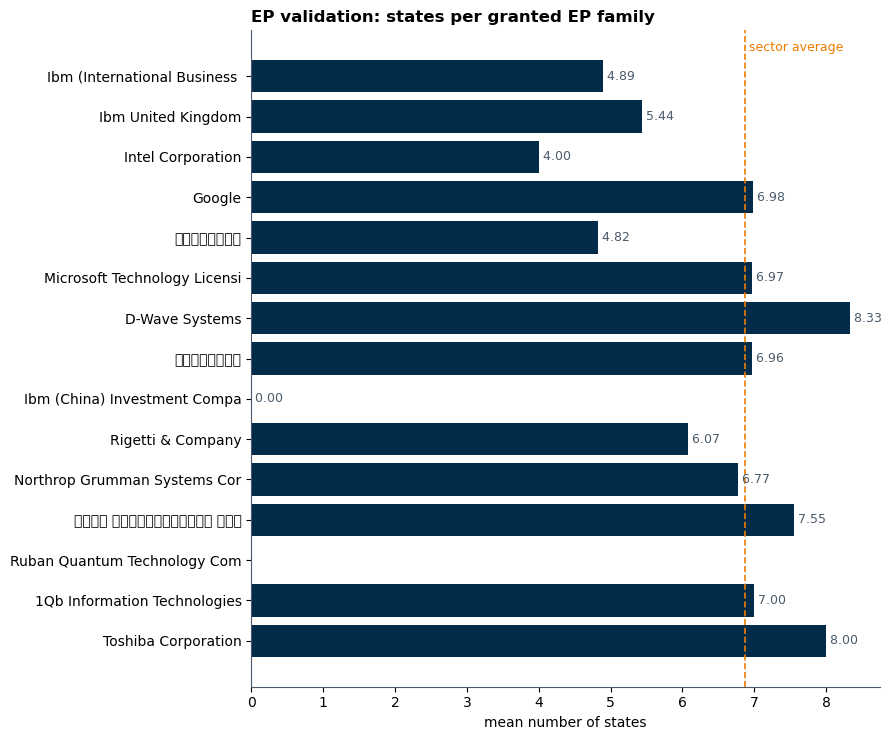

In [29]:
ep_g = ep[ep.granted == "Y"].copy()
ep_g["states"] = ep_g.appln_id.map(states).fillna(0)
families["ep_states"] = families.docdb_family_id.map(ep_g.groupby("docdb_family_id").states.max())
ep_states = per_firm("ep_states")

firm_bars(ep_states, "EP validation: states per granted EP family", "mean number of states",
          ref=families.ep_states.mean(), ref_label="sector average")

**Offices** tell where the firm *applied* (USA, China, Japan...); **validated states** tell where in Europe it *kept* the granted patent. A firm can file everywhere and then validate only in Germany: a cheaper strategy, and a weaker signal.

### 7.4 Refinement: quadrilateral families, the Clarivate measure

Counting offices treats every office the same: Brazil counts as much as the United States. Clarivate looks instead at the **four main markets**, the offices of China (CN), Europe (EP), Japan (JP) and the United States (US). A **quadrilateral family** is filed at all four: an expensive choice, made only for inventions with a global market. In quantum computing, with the race between the US, China, Europe and Japan, it is a natural lens.

$$\text{Quadrilateral share}_f=\frac{\text{families of } f \text{ filed at CN, EP, JP and US}}{\text{families of } f}$$



Quadrilateral families in the sector: 11%


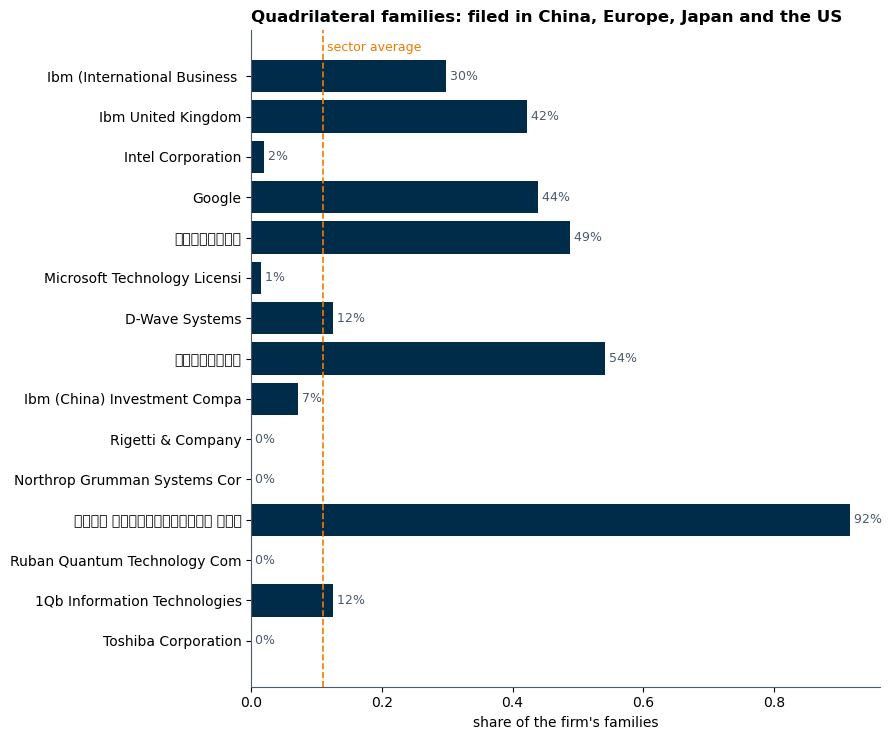

In [30]:
QUAD = {"CN", "EP", "JP", "US"}

quad = national.groupby("docdb_family_id").appln_auth.apply(lambda offices: QUAD.issubset(set(offices)))
families["quadrilateral"] = families.docdb_family_id.map(quad).fillna(False).astype(int)
quadrilateral_share = per_firm("quadrilateral").rename("quadrilateral_share")

print(f"Quadrilateral families in the sector: {families.quadrilateral.mean():.0%}")
firm_bars(quadrilateral_share, "Quadrilateral families: filed in China, Europe, Japan and the US",
          "share of the firm's families", fmt="{:.0%}", ref=families.quadrilateral.mean(), ref_label="sector average")

## 8. From four indicators to one ranking

Each firm now has four numbers. To rank the firms we need **one** number per firm, and we get there in three steps:

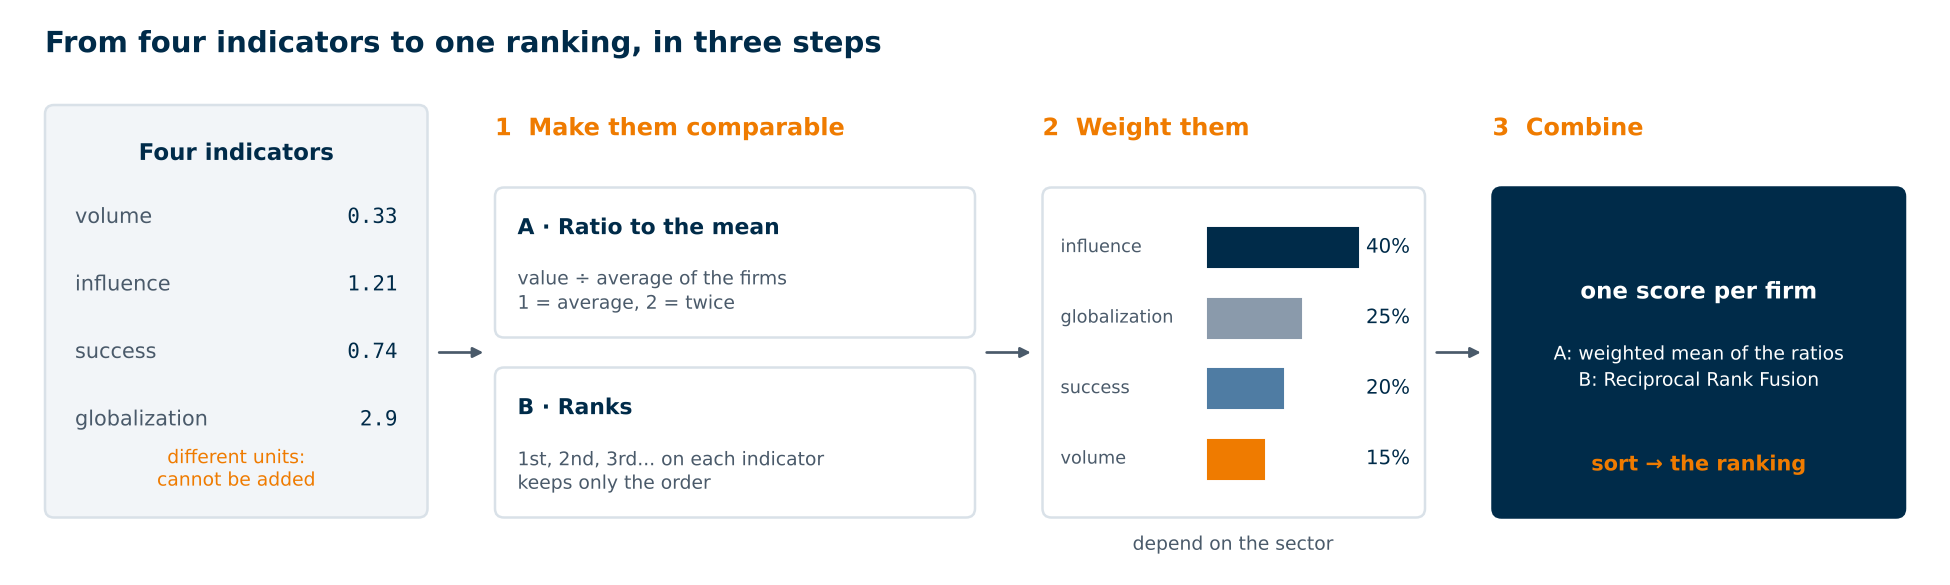

1. **make the indicators comparable**, because they are in different units;
2. **choose the weights**: how much each dimension counts for your sector;
3. **combine** them into one score, and sort.

The starting point is the indicator table: one row per firm, one column per basic indicator. The refinements go in a second table, `extras`, used in section 10.

In [31]:
INDICATORS = ["volume", "influence", "success", "globalization"]

firms = pd.concat([n_families.reindex(TOP).rename("families"), volume, influence, success, globalization], axis=1)
extras = pd.concat([volume_change, volume_recent, by_window, applicant_share, blocking_share, blocking_power,
                    success_ep, family_success, family_size, ep_states, quadrilateral_share], axis=1)
firms.round(3)

,families,volume,influence,success,globalization
firm,,,,,
IBM (INTERNATIONAL BUSINESS MACHINES CORPORATION),188,0.100,0.950,0.911,2.654
IBM UNITED KINGDOM,123,0.065,1.051,0.897,3.415
INTEL CORPORATION,104,0.055,1.562,0.575,1.288
GOOGLE,91,0.048,0.989,0.827,4.703
国际商业机器公司,88,0.047,1.070,0.944,3.818
MICROSOFT TECHNOLOGY LICENSING,70,0.037,0.890,0.845,2.129
D-WAVE SYSTEMS,64,0.034,1.397,0.832,1.781
谷歌有限责任公司,61,0.032,0.949,0.825,5.410
IBM (CHINA) INVESTMENT COMPANY,42,0.022,1.306,0.913,3.905


### 8.1 Why the numbers must be made comparable first

If we ranked the firms on **one** indicator, we would simply sort the table. The problem comes when we put four indicators together: they are in different units.

| Indicator | Unit | Typical values (look at your table) |
|---|---|---|
| volume | share of the sector | a few percent |
| influence | ratio to the mean of the cohort | around 1 |
| success | share of applications | between 0 and 1 |
| globalization | number of offices | 1 – 10 |

If we simply added the raw values, the indicator with the **largest numbers** (globalization) would decide the ranking, and volume (a few percent) would count almost nothing: an accident of units, not a choice of ours.

### 8.2 Step 1 · Make the indicators comparable: two solutions

| | **A · Ratio to the mean** | **B · Ranks** |
|---|---|---|
| How | divide each value by the average of the scored firms | on each indicator, sort the firms: 1st, 2nd, 3rd... |
| Reads as | "1.4 = 40% above the average firm" | "3rd of 15 on influence" |
| Keeps | the **size of the gaps** | only the **order** |

**A · Ratio to the mean.** The same idea as the normalisation of influence (5.1): there each family was compared with the average of its cohort, here each firm with the average firm. The map shows the ratios: blue above the average firm, red below.

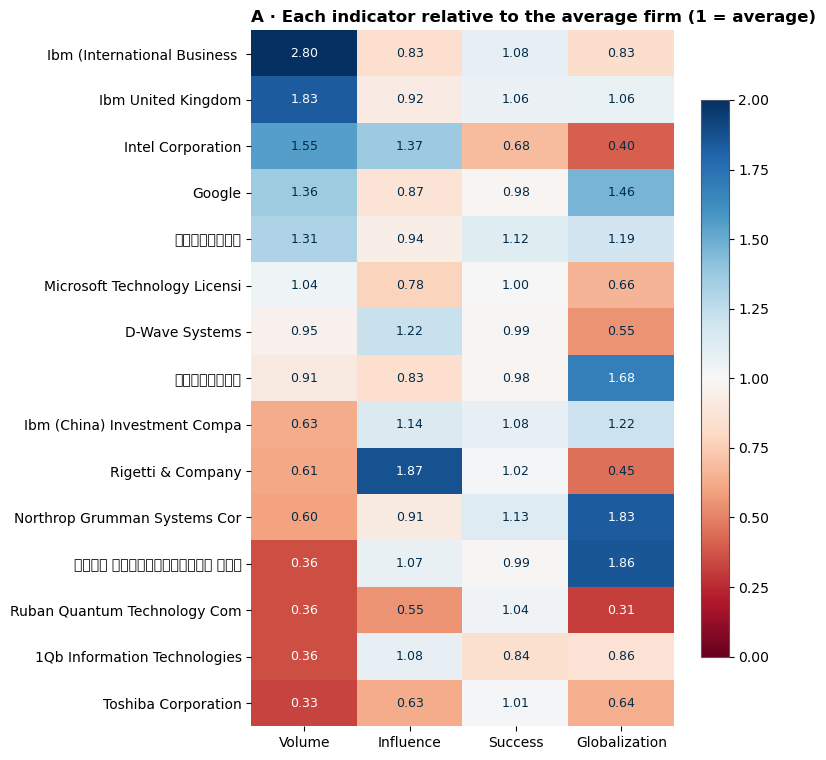

In [32]:
relative = firms[INDICATORS] / firms[INDICATORS].mean()              # A: 1 = average firm

fig, ax = plt.subplots(figsize=(8, 0.42 * len(relative) + 1.4))
im = ax.imshow(relative.values, cmap="RdBu", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(INDICATORS)), [k.capitalize() for k in INDICATORS])
ax.set_yticks(range(len(relative)), [SHORT[f] for f in relative.index])
for i in range(relative.shape[0]):
    for j in range(relative.shape[1]):
        v = relative.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v - 1) > 0.6 else NAVY)
ax.spines[:].set_visible(False)
ax.set_title("A · Each indicator relative to the average firm (1 = average)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

Read the map **by rows**: a firm blue everywhere is strong on all four dimensions; a firm blue only on volume is big but not necessarily valuable. Look at the volume column: a value far above 2 means one firm is much bigger than the others (very likely in quantum computing, where a few giants hold a large part of the portfolios).

**B · Ranks.** On each indicator we give position 1 to the best firm, 2 to the second, and so on. The best way to see ranks is a **leaderboard**: one column per indicator, the firms sorted from the 1st (top) to the last (bottom). Each firm keeps its colour, and a thin line follows it from one column to the next: a firm that stays near the top across the columns is strong everywhere; a line that zigzags is a firm strong on some dimensions and weak on others.

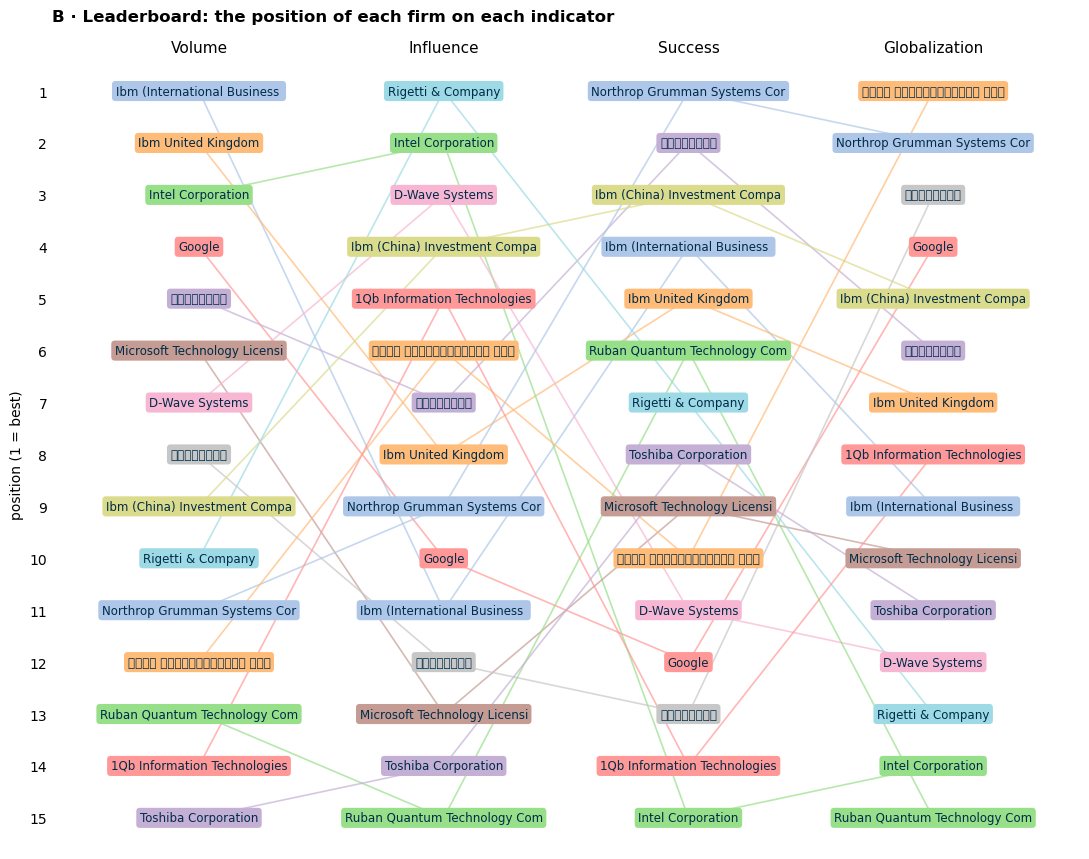

In [33]:
positions = firms[INDICATORS].rank(ascending=False, method="min")    # B: 1 = best firm on that indicator
shown = firms[INDICATORS].rank(ascending=False, method="first")       # same order, ties split only for the drawing

colour = {f: plt.cm.tab20(2 * k % 20 + 1) for k, f in enumerate(TOP)}
fig, ax = plt.subplots(figsize=(11, 0.5 * len(TOP) + 1.2))
for f in TOP:
    ax.plot(range(len(INDICATORS)), shown.loc[f, INDICATORS], color=colour[f], lw=1.2, alpha=0.7, zorder=1)
    for j, k in enumerate(INDICATORS):
        ax.text(j, shown.loc[f, k], SHORT[f], ha="center", va="center", fontsize=8.5, color=NAVY, zorder=2,
                bbox=dict(boxstyle="round,pad=0.3", fc=colour[f], ec="none"))
ax.set_xlim(-0.6, len(INDICATORS) - 0.4)
ax.set_ylim(len(TOP) + 0.6, 0.4)
ax.set_xticks(range(len(INDICATORS)), [k.capitalize() for k in INDICATORS], fontsize=11)
ax.xaxis.tick_top()
ax.set_yticks(range(1, len(TOP) + 1))
ax.set_ylabel("position (1 = best)")
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.set_title("B · Leaderboard: the position of each firm on each indicator", pad=28)
plt.tight_layout()
plt.show()

### 8.3 Ratio to the mean or ranks? How to choose

The two solutions answer **different questions**. The ratio to the mean asks *how much* better a firm is; ranks ask *where* a firm stands, whatever the size of the gaps.

| Choose the **ratio to the mean** when... | Choose **ranks** when... |
|---|---|
| the size of the gaps is part of the answer: the bank wants to know if the leader is a little or a lot ahead | the question is "who is first?" (a shortlist of targets) |
| the indicators are not too skewed: no firm far above 2-3 times the average | one indicator is very skewed (a giant firm): with the mean it would decide the ranking alone |
| each firm has enough patents for its values to be reliable: small differences are real | the values are noisy: you trust the order more than the exact numbers |

**Watch out with the mean**: a skewed indicator can be tamed by transforming it before the ratio (e.g. the logarithm of volume).

**Watch out with ranks**: tiny differences become full positions (a success rate of 0.71 against 0.73 is one position, like 0.50 against 0.90).

### 8.4 Step 2 · Choose the weights

The weights $w_k$ say how much each dimension counts; they sum to 1. Equal weights ($w_k = 1/4$) are also a choice: they say that size counts as much as impact.

**There is no universal set of weights: each sector needs its own**, because sectors use patents differently:

| Sector | How patents are used | What should weigh more |
|---|---|---|
| Pharmaceuticals, biotech | few patents, each protecting a whole product; long examinations; protection in many countries | **success**, **globalization**, influence; volume much less |
| Electronics, telecom | thousands of patents per firm, thickets, standards, cross-licensing | **volume** and **globalization**; citations are noisy |
| Consumer goods, e.g. coffee capsules | designs easy to copy, fast entry of competitors, litigation | **influence** and blocking patents (5.4), success |
| Software, AI | short life of the technology, many applications still pending | short citation windows (5.2), volume over time (4.2) |
| **Quantum computing** | pre-commercial, a race for foundational positions: patents are filed years before products; young portfolios; strategic rivalry between countries | **influence** (who sets the technological reference), **globalization** (US, China, Europe, Japan); **volume** counts as the size of the position; **success** less (many applications are still pending) |

The weights below are the **proposal of this notebook for quantum computing**, to be defended in the deck: say where yours come from (your reasoning, the literature, experts you asked). Section 9 shows how much the ranking depends on them.

In [34]:
WEIGHTS = {"influence": 0.35, "globalization": 0.25, "volume": 0.25, "success": 0.15}
print("Sum of the weights:", round(sum(WEIGHTS.values()), 3))

Sum of the weights: 1.0


### 8.5 Step 3 · Combine

Now the comparable indicators become **one score per firm**. Each of the two solutions has its own way to combine.

#### A · Weighted mean of the ratios

$$\text{Score}_f=100\cdot\sum_k w_k\cdot\frac{x_{f,k}}{\bar x_k}\qquad(100 = \text{average firm})$$

It is **compensatory**: a lot of one indicator makes up for little of another. For example, a firm 4.4 times bigger than the average gets 100 × 0.25 × 4.4 = 110 points from volume alone, more than the whole score of an average firm.

#### B · Reciprocal Rank Fusion (RRF) of the ranks

Combining several rankings into one is a classic problem of **search engines**: several algorithms each rank the web pages, and one list must be shown. **Reciprocal Rank Fusion** (Cormack et al. 2009: https://dl.acm.org/doi/10.1145/1571941.1572114) is the standard solution, and it works the same for our firms: each indicator is one ranking. Every position is turned into points with $1/(c+\text{position})$, then the points are added with the weights:

$$\text{RRF}_f=100\cdot\sum_k w_k\cdot\frac{c+1}{c+\text{position}_{f,k}}\qquad(100 = \text{first on every indicator})$$

- being **at the top** of an indicator gives many points; moving up in the middle of the list gives few;
- $c$ sets how much the top counts. The original paper used $c = 60$ for lists of hundreds of web pages; with a few firms we use $c$ = number of firms. The table shows how many points each position is worth (1st = 100):

In [35]:
RRF_C = len(TOP)                         # the constant c of RRF: the number of firms

pos = np.arange(1, len(TOP) + 1)
pd.DataFrame({"points": (100 * (RRF_C + 1) / (RRF_C + pos)).round(0).astype(int)},
             index=pd.Index(pos, name="position")).T

position,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
points,100,94,89,84,80,76,73,70,67,64,62,59,57,55,53


**A worked example: the giant and the specialist.** Two firms, equal weights. Firm X is the largest of the sector but average on the rest; firm Y is small but excellent.

| | volume | influence | success | globalization | A · Mean | B · RRF ($c$=10) |
|---|---|---|---|---|---|---|
| X: position (ratio) | 1st (4.4) | 5th (1.1) | 5th (1.0) | 5th (0.9) | **185** | 80 |
| Y: position (ratio) | 8th (0.6) | 1st (1.5) | 1st (1.3) | 2nd (1.2) | 115 | **88** |

The mean puts X first: its size (4.4 times the average) compensates for everything else. RRF puts Y first: it is at the top of three indicators out of four. Neither is wrong: they answer different questions (8.3). This is the **giant and the specialist** of quantum computing: a big tech group with a huge portfolio against a start-up with a few, much cited families.

One function computes both, so that sections 9 and 10 can reuse it:

In [36]:
def combine(table, weights, method):
    """One score per firm, higher = better. 'mean': 100 = average firm. 'rrf': 100 = first on every indicator."""
    w = pd.Series(weights, dtype=float)
    w = w / w.sum()
    t = table[w.index]
    if method == "mean":
        return 100 * (t / t.mean() * w).sum(axis=1)
    if method == "rrf":
        pos = t.rank(ascending=False, method="min")           # 1 = best on each indicator
        return 100 * (w * (RRF_C + 1) / (RRF_C + pos)).sum(axis=1)
    raise ValueError("method must be 'mean' or 'rrf'")


def final_rank(scores, method=None):
    """From scores to the ranking: 1 = best firm."""
    return scores.rank(ascending=False, method="min").astype(int)


both = pd.DataFrame({"A · mean": combine(firms, WEIGHTS, "mean"), "B · RRF": combine(firms, WEIGHTS, "rrf")})
both["rank A"] = final_rank(both["A · mean"])
both["rank B"] = final_rank(both["B · RRF"])
positions.astype(int).add_prefix("pos. ").join(both.round(1)).sort_values("rank B").rename(index=SHORT)

,pos. volume,pos. influence,pos. success,pos. globalization,A · mean,B · RRF,rank A,rank B
firm,,,,,,,,
Ibm (China) Investment Compa,9,4,3,5,102.2,79.5,10,1
国际商业机器公司,5,7,2,6,112.0,78.6,4,2
Ibm United Kingdom,2,8,5,7,120.5,78.1,2,3
Northrop Grumman Systems Cor,11,9,1,2,109.5,77.2,5,4
Intel Corporation,3,2,15,14,106.8,77.0,9,5
Rigetti & Company,10,1,7,13,107.2,76.2,8,6
グーグル エルエルシーＧｏｏｇｌｅ Ｌｌｃ,12,6,10,1,107.8,76.1,7,7
Ibm (International Business,1,11,4,9,136.0,75.8,1,8
Google,4,10,12,4,115.5,73.4,3,9


**How to read the table.** The first four columns are the positions on each indicator; then the two scores and their rankings.

- A firm with the **same rank in A and B** is placed the same way whatever the method: a solid result.
- A firm **much higher in A than in B** is far ahead on one indicator (often volume): the mean rewards the size of its lead, RRF does not.

With the mean we can also show **what makes** each score: each indicator contributes $100\cdot w_k\cdot x_{f,k}/\bar x_k$.

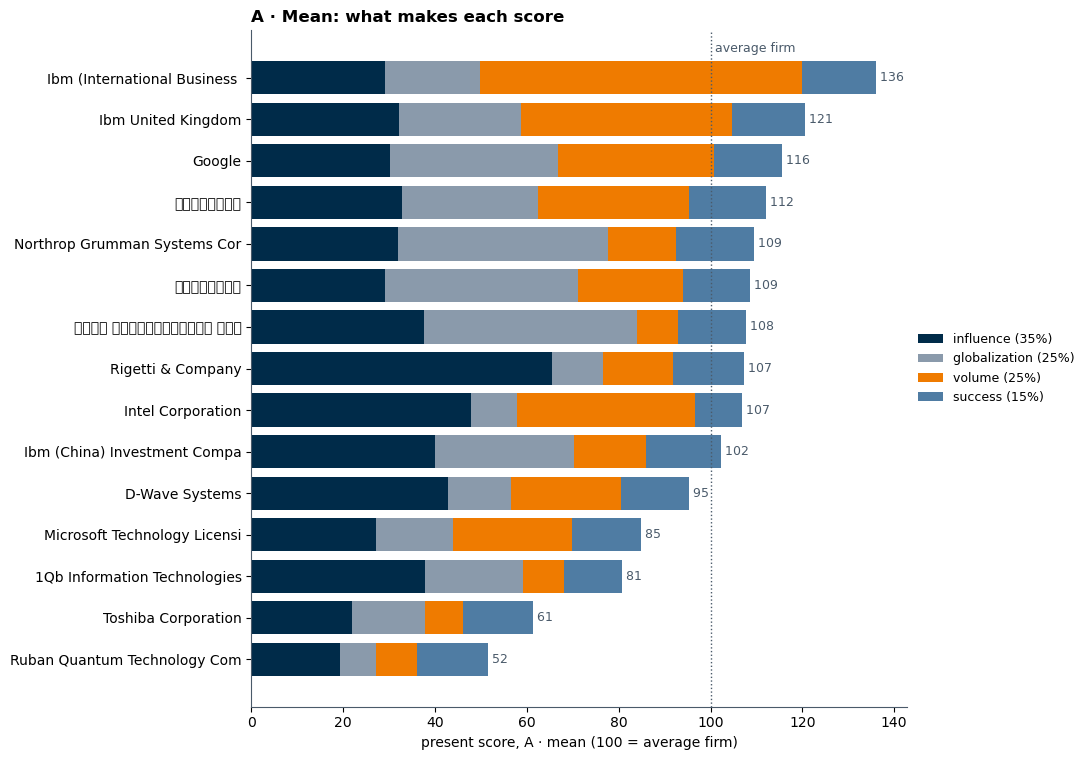

In [37]:
w = pd.Series(WEIGHTS)
contrib = 100 * relative[w.index] * w
order = combine(firms, WEIGHTS, "mean").sort_values().index

fig, ax = plt.subplots(figsize=(11, 0.42 * len(order) + 1.4))
left = np.zeros(len(order))
colours = {"influence": NAVY, "globalization": MID, "success": BLUE, "volume": ORANGE}
for k in w.index:
    vals = contrib.loc[order, k].values
    ax.barh([SHORT[f] for f in order], vals, left=left, color=colours[k], label=f"{k} ({w[k]:.0%})")
    left += vals
for y, x in enumerate(left):
    ax.text(x, y, f" {x:.0f}", va="center", fontsize=9, color=GREY)
ax.axvline(100, color=GREY, ls=":", lw=1)
ax.text(100, len(order) - 0.45, " average firm", color=GREY, fontsize=9, va="bottom")
ax.set_xlabel("present score, A · mean (100 = average firm)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
ax.set_title("A · Mean: what makes each score")
plt.tight_layout()
plt.show()

#### The final ranking

Choose the method with `METHOD`, and write in the deck **why**, using the guide of 8.3.

In [38]:
METHOD = "rrf"              # "mean" (A) or "rrf" (B)

firms["score"] = combine(firms, WEIGHTS, METHOD)
firms["rank"] = final_rank(firms.score)
firms.sort_values("rank")[["families", "score", "rank"]].round(1).rename(index=SHORT)

,families,score,rank
firm,,,
Ibm (China) Investment Compa,42,79.5,1
国际商业机器公司,88,78.6,2
Ibm United Kingdom,123,78.1,3
Northrop Grumman Systems Cor,40,77.2,4
Intel Corporation,104,77.0,5
Rigetti & Company,41,76.2,6
グーグル エルエルシーＧｏｏｇｌｅ Ｌｌｃ,24,76.1,7
Ibm (International Business,188,75.8,8
Google,91,73.4,9


## 9. Is the ranking robust?

The method and the weights are assumptions, and a ranking that changes completely with small changes of the assumptions tells us little. Section 8.5 already compared the two **methods** with the same weights. Here we keep the chosen method and change the **weights**: equal, size first, impact first, and leaving one indicator out at a time.

In [39]:
SCHEMES = {
    "equal": {k: 1 for k in INDICATORS},
    "ours": WEIGHTS,
    "impact first": {"influence": 0.55, "globalization": 0.20, "volume": 0.15, "success": 0.10},
    "size first": {"influence": 0.15, "globalization": 0.20, "volume": 0.50, "success": 0.15},
}
for k in INDICATORS:
    SCHEMES[f"without {k}"] = {j: 1 for j in INDICATORS if j != k}

by_weights = pd.DataFrame({name: final_rank(combine(firms, w, METHOD), METHOD) for name, w in SCHEMES.items()})
by_weights.rename(index=SHORT).sort_values("ours")

,equal,ours,impact first,size first,without volume,without influence,without success,without globalization
firm,,,,,,,,
Ibm (China) Investment Compa,3,1,3,6,2,5,5,4
国际商业机器公司,1,2,6,3,3,3,6,1
Ibm United Kingdom,4,3,7,2,6,4,2,3
Northrop Grumman Systems Cor,2,4,8,7,1,1,8,7
Intel Corporation,9,5,2,4,12,10,1,6
Rigetti & Company,7,6,1,12,5,11,9,5
グーグル エルエルシーＧｏｏｇｌｅ Ｌｌｃ,6,7,5,9,4,7,3,11
Ibm (International Business,5,8,10,1,7,2,7,2
Google,8,9,11,5,9,6,4,9


Each column is one ranking (1 = best). How close is each one to ours (Spearman: 1 = same order)?

In [40]:
by_weights.corr(method="spearman")["ours"].drop("ours").round(2).sort_values().to_frame("correlation with our ranking")

,correlation with our ranking
without influence,0.71
size first,0.72
impact first,0.74
without success,0.79
without globalization,0.82
without volume,0.85
equal,0.92


How to read it:

- firms that stay in the **top positions in every ranking**, here and in 8.5, are a safe recommendation;
- a firm that jumps when one indicator is dropped owes its position to that indicator: say so in the deck;
- correlations above about 0.8 mean the ranking does not depend much on the assumptions. If they are low, your assumptions *are* your result, and you must defend them carefully.

## 10. Using a refinement in the score

A refinement can **replace** a basic indicator (a better measure of the same thing) or be **added** as a fifth one. Three examples for quantum computing:

- replace globalization (offices) with the **quadrilateral share** (7.4), the Clarivate measure, if your bank cares about the main world markets (US, China, Europe, Japan);
- replace the pooled success with the **success by invention** (6.3), which does not depend on how many applications a firm files in each office;
- add **blocking patents** (5.4): in a race for foundational positions, blocking power is value.

Refinements that are missing for some firms (EP success, EP states) cannot enter the score without a rule for the missing values: use them to *read* the ranking, not to build it.

In [41]:
table = pd.concat([firms[INDICATORS], extras], axis=1)

variants = {
    "basic (ours)": WEIGHTS,
    "quadrilateral instead of offices": {"influence": 0.35, "quadrilateral_share": 0.25, "volume": 0.25, "success": 0.15},
    "success by invention": {"influence": 0.35, "globalization": 0.25, "volume": 0.25, "family_success": 0.15},
    "plus blocking patents": {"influence": 0.25, "blocking_share": 0.15, "globalization": 0.20, "volume": 0.25, "success": 0.15},
}
compare = pd.DataFrame({name: final_rank(combine(table, w, METHOD), METHOD) for name, w in variants.items()})
compare.rename(index=SHORT).sort_values("basic (ours)")

,basic (ours),quadrilateral instead of offices,success by invention,plus blocking patents
firm,,,,
Ibm (China) Investment Compa,1,7,3,1
国际商业机器公司,2,1,2,3
Ibm United Kingdom,3,2,1,4
Northrop Grumman Systems Cor,4,12,4,7
Intel Corporation,5,3,5,6
Rigetti & Company,6,5,6,2
グーグル エルエルシーＧｏｏｇｌｅ Ｌｌｃ,7,8,8,5
Ibm (International Business,8,4,7,8
Google,9,9,9,9


If a refinement moves a firm by several positions, it tells you something the basic indicator missed: explain it in the deck.

## 11. Save the score

The score goes to the next step of the deck (the Magic Quadrant). We save the firms with their indicators, score and rank, and the refinements.

In [42]:
result = pd.concat([firms, extras], axis=1).sort_values("rank")
result.index.name = "firm"
result.to_csv(OUT / "present_score_quantum.csv")
print(f"Saved {len(result)} firms in {OUT / 'present_score_quantum.csv'}")
print("Design decisions to write in the appendix:",
      dict(window=WINDOW, n_firms=N_FIRMS, min_families=MIN_FAMILIES, cohort=COHORT, min_cohort=MIN_COHORT,
           weights=WEIGHTS, method=METHOD))

Saved 15 firms in outputs/present_score_quantum.csv
Design decisions to write in the appendix: {'window': (2013, 2018), 'n_firms': 15, 'min_families': 10, 'cohort': ['cpc4', 'priority_year'], 'min_cohort': 5, 'weights': {'influence': 0.35, 'globalization': 0.25, 'volume': 0.25, 'success': 0.15}, 'method': 'rrf'}
